# EEM Paper: Results Visualization\n\n**Impact of German electricity market zone splitting on spatial distribution of charging loads**\n\nThree research questions:\n1. COâ‚‚ emissions on German highways\n2. Charging demand distribution North vs South\n3. Infrastructure overcapacity from split timing

In [530]:
import yaml, re, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from collections import defaultdict

SCRIPT_DIR = Path('.').resolve()
os.chdir(SCRIPT_DIR)

RESULTS_DIR = SCRIPT_DIR / 'results' / 'eem_scenarios'
INPUT_DIR = SCRIPT_DIR / 'input_data' / 'eem_scenarios'
FIGURES_DIR = SCRIPT_DIR / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

# EEM manuscript folder — figures are also saved here for LaTeX
EEM_DIR = SCRIPT_DIR.parent.parent / '-EEM-Impact-of-German-electricity-market-zone-splitting-on-spatial-distribution-of-charging-loads'
if EEM_DIR.exists():
    print(f"EEM manuscript dir: {EEM_DIR}")
else:
    print(f"WARNING: EEM dir not found at {EEM_DIR}")

# Zone definitions (TSO boundaries)
DE_NORTH = {'DE30','DE40','DE50','DE60','DE80','DE91','DE92','DE93','DE94',
            'DEF0','DED2','DED4','DED5','DEE0','DEG0'}
DE_SOUTH = {'DE11','DE12','DE13','DE14','DE21','DE22','DE23','DE24','DE25','DE26','DE27',
            'DE71','DE72','DE73','DEA1','DEA2','DEA3','DEA4','DEA5',
            'DEB1','DEB2','DEB3','DEC0'}

# Model uses 4-year time steps: indices 1-11 map to 2020, 2024, ..., 2060
TIME_STEP = 4
MODELED_YEARS = list(range(2020, 2061, TIME_STEP))  # [2020, 2024, 2028, ..., 2060]
IDX_TO_YEAR = {i+1: y for i, y in enumerate(MODELED_YEARS)}
print(f"Modeled years ({len(MODELED_YEARS)}): {MODELED_YEARS}")

# Scenario labels match manuscript Table I (scenario matrix)
SCENARIOS = {
    'DE_unified': {'label': 'Baseline', 'spread': 0, 'timing': None, 'color': 'black', 'ls': '-'},
    'DE_split_low_from2032':  {'label': 'L-2032',  'spread': 5,  'timing': 2032, 'color': '#2196F3', 'ls': '-'},
    'DE_split_low_from2040':  {'label': 'L-2040',  'spread': 5,  'timing': 2040, 'color': '#2196F3', 'ls': ':'},
    'DE_split_mid_from2032':  {'label': 'M-2032',  'spread': 10, 'timing': 2032, 'color': '#FF9800', 'ls': '-'},
    'DE_split_mid_from2040':  {'label': 'M-2040',  'spread': 10, 'timing': 2040, 'color': '#FF9800', 'ls': ':'},
    'DE_split_high_from2032': {'label': 'H-2032',  'spread': 20, 'timing': 2032, 'color': '#F44336', 'ls': '-'},
    'DE_split_high_from2040': {'label': 'H-2040',  'spread': 20, 'timing': 2040, 'color': '#F44336', 'ls': ':'},
}

def save_eem(fig, name):
    """Save figure to both figures/ and EEM manuscript folder."""
    fig.savefig(FIGURES_DIR / name, bbox_inches='tight', dpi=300)
    if EEM_DIR.exists():
        fig.savefig(EEM_DIR / name, bbox_inches='tight', dpi=300)
        print(f"  -> also saved to EEM: {name}")

print("Configuration loaded.")

EEM manuscript dir: D:\AntoniaMariaG\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\-EEM-Impact-of-German-electricity-market-zone-splitting-on-spatial-distribution-of-charging-loads
Modeled years (11): [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]
Configuration loaded.


## Data Loading\nLoad geographic mappings and result variables (s, q_fuel_infr_plus, h) for all 10 scenarios.

In [531]:
# Build geo_id -> zone mapping
geos = yaml.safe_load(open(INPUT_DIR / 'DE_unified' / 'GeographicElement.yaml'))
geo_id_to_nuts2 = {}
geo_id_to_zone = {}
for g in geos:
    nuts2 = g.get('nuts2_region', '')
    geo_id_to_nuts2[g['id']] = nuts2
    if nuts2 in DE_NORTH:
        geo_id_to_zone[g['id']] = 'DE-North'
    elif nuts2 in DE_SOUTH:
        geo_id_to_zone[g['id']] = 'DE-South'
    else:
        geo_id_to_zone[g['id']] = nuts2[:2] if len(nuts2) >= 2 else '??'

# TechVehicle -> technology mapping
tv_list = yaml.safe_load(open(INPUT_DIR / 'DE_unified' / 'TechVehicle.yaml'))
tv_id_to_tech = {t['id']: t['technology'] for t in tv_list}

print(f"Nodes: {sum(1 for v in geo_id_to_zone.values() if v=='DE-North')} North, "
      f"{sum(1 for v in geo_id_to_zone.values() if v=='DE-South')} South, "
      f"{sum(1 for v in geo_id_to_zone.values() if v not in ('DE-North','DE-South'))} other")

Nodes: 15 North, 23 South, 43 other


In [532]:
def find_result_file(scenario, varname):
    """Find the LATEST result YAML file for a scenario and variable."""
    sc_dir = RESULTS_DIR / scenario
    files = sorted(sc_dir.glob(f'*_{varname}_dict.yaml'))
    return files[-1] if files else None

# ---- Build prkg mapping from Julia's actual Set ordering ----
_prkg_ordering_file = SCRIPT_DIR / 'prkg_ordering.txt'
if _prkg_ordering_file.exists():
    PRKG_IDX_MAP = {}
    with open(_prkg_ordering_file) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split('\t')
            idx = int(parts[0])
            t = parts[1].strip('()')
            vals = [int(x.strip()) for x in t.split(',')]
            PRKG_IDX_MAP[idx] = tuple(vals)
    print(f"Loaded prkg ordering from Julia: {len(PRKG_IDX_MAP)} entries")
else:
    print("WARNING: prkg_ordering.txt not found!")
    PRKG_IDX_MAP = {}

# ---- Geo ID axis mapping (for q_fuel_infr_plus which still uses CartesianIndex) ----
_geos_for_axis = yaml.safe_load(open(INPUT_DIR / 'DE_unified' / 'GeographicElement.yaml'))
GEO_IDS_SORTED = sorted([g['id'] for g in _geos_for_axis])
GEO_POS_TO_ID = {pos+1: gid for pos, gid in enumerate(GEO_IDS_SORTED)}
print(f"Geo axis: {len(GEO_IDS_SORTED)} nodes, ids {GEO_IDS_SORTED[0]}..{GEO_IDS_SORTED[-1]}")

FT_ELECTRIC = {1, 2}
FT_DIESEL = {3}

# Regex patterns for old CartesianIndex format
PAT_CI5 = re.compile(r'CartesianIndex\((\d+),\s*(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\)')
PAT_Q = re.compile(r'CartesianIndex\((\d+),\s*(\d+),\s*(\d+)\)')

# Regex for new tuple format of s:
#   (year, (0, odpair_id, path_id, geo_id), tv_id, (fuel_id, infr_type_id), gen): value
PAT_S_TUPLE = re.compile(
    r'\((\d+),\s*\(\d+,\s*\d+,\s*\d+,\s*(\d+)\),\s*(\d+),\s*\((\d+),\s*(\d+)\),\s*\d+\)')

# Regex for new tuple format of h:  (year, odpair_id, tv_id, gen): value
PAT_H_TUPLE = re.compile(r'\((\d+),\s*\d+,\s*(\d+),\s*\d+\)')

# Regex for new tuple format of f:
#   (year, (prod, odpair, path), (mode, tv), gen): value
PAT_F_TUPLE = re.compile(
    r'\((\d+),\s*\(\d+,\s*(\d+),\s*\d+\),\s*\(\d+,\s*(\d+)\),\s*\d+\)')


def _detect_format(fpath):
    """Peek at first non-empty line to detect CartesianIndex vs tuple format."""
    with open(fpath) as f:
        for line in f:
            line = line.strip()
            if line:
                return 'cartesian' if line.startswith('CartesianIndex') else 'tuple'
    return 'unknown'


def load_s_by_zone(scenario):
    """Load charging energy (s) aggregated by zone and year.
    Auto-detects old CartesianIndex format vs new tuple format."""
    fpath = find_result_file(scenario, 's')
    if fpath is None:
        print(f"  WARNING: No s_dict for {scenario}")
        return {}

    fmt = _detect_format(fpath)
    zone_year = defaultdict(lambda: defaultdict(float))

    with open(fpath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            sep = line.rfind(': ')
            if sep < 0:
                continue
            val = float(line[sep+2:])

            if fmt == 'cartesian':
                m = PAT_CI5.match(line[:sep])
                if not m:
                    continue
                y_idx = int(m.group(1))
                prkg_idx = int(m.group(2))
                tv_idx = int(m.group(3))
                fl_idx = int(m.group(4))
                if tv_idx != 2 or fl_idx not in (1, 2):
                    continue
                year = IDX_TO_YEAR.get(y_idx)
                prkg = PRKG_IDX_MAP.get(prkg_idx)
                if year is None or prkg is None:
                    continue
                geo_id = prkg[3]
            else:  # tuple format
                m = PAT_S_TUPLE.match(line[:sep])
                if not m:
                    continue
                year = int(m.group(1))
                geo_id = int(m.group(2))
                tv_id = int(m.group(3))
                fuel_id = int(m.group(4))
                # tv_id=1 is BEV, fuel_id=0 is electricity
                if tv_id != 1 or fuel_id != 0:
                    continue

            zone = geo_id_to_zone.get(geo_id, 'Other')
            zone_year[zone][year] += val

    return zone_year


def load_q_by_zone(scenario, ft_filter=None):
    """Load infrastructure additions (q_fuel_infr_plus) by zone and year.
    Still uses CartesianIndex format."""
    fpath = find_result_file(scenario, 'q_fuel_infr_plus')
    if fpath is None:
        print(f"  WARNING: No q_fuel_infr_plus for {scenario}")
        return {}
    zone_year = defaultdict(lambda: defaultdict(float))
    with open(fpath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            sep = line.rfind(': ')
            if sep < 0:
                continue
            m = PAT_Q.match(line[:sep])
            if not m:
                continue
            y_idx, ft_idx, geo_pos = int(m.group(1)), int(m.group(2)), int(m.group(3))
            if ft_filter is not None and ft_idx not in ft_filter:
                continue
            year = IDX_TO_YEAR.get(y_idx)
            if year is None:
                continue
            geo_id = GEO_POS_TO_ID.get(geo_pos)
            if geo_id is None:
                continue
            zone = geo_id_to_zone.get(geo_id, 'Other')
            zone_year[zone][year] += float(line[sep+2:])
    return zone_year


def load_h_by_tech(scenario):
    """Load fleet stock (h) by technology and year.
    Auto-detects old vs new format."""
    fpath = find_result_file(scenario, 'h')
    if fpath is None:
        return {}

    fmt = _detect_format(fpath)
    tech_year = defaultdict(lambda: defaultdict(float))

    with open(fpath, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            sep = line.rfind(': ')
            if sep < 0:
                continue
            m = PAT_H_TUPLE.match(line[:sep])
            if not m:
                continue
            year, tv_id = int(m.group(1)), int(m.group(2))
            tech = tv_id_to_tech.get(tv_id, -1)
            tech_year[tech][year] += float(line[sep+2:])

    return tech_year


print("\nHelper functions defined (auto-detecting CartesianIndex vs tuple format).")

Loaded prkg ordering from Julia: 16136 entries
Geo axis: 81 nodes, ids 0..80

Helper functions defined (auto-detecting CartesianIndex vs tuple format).


In [533]:
%%time
# Load all scenario data
# q_elec: electric charging infrastructure only (ft_idx 2=slow, 3=fast)
# q_diesel: diesel fueling infrastructure only (ft_idx 1)
all_s, all_q_elec, all_q_diesel, all_h = {}, {}, {}, {}
for sc in SCENARIOS:
    print(f"  Loading {sc}...")
    all_s[sc] = load_s_by_zone(sc)
    all_q_elec[sc] = load_q_by_zone(sc, ft_filter=FT_ELECTRIC)
    all_q_diesel[sc] = load_q_by_zone(sc, ft_filter=FT_DIESEL)
    all_h[sc] = load_h_by_tech(sc)
print("Done.")

  Loading DE_unified...
  Loading DE_split_low_from2032...
  Loading DE_split_low_from2040...
  Loading DE_split_mid_from2032...
  Loading DE_split_mid_from2040...
  Loading DE_split_high_from2032...
  Loading DE_split_high_from2040...
Done.
CPU times: total: 24 s
Wall time: 25 s


## Summary Table\nKey metrics at 2040 for all scenarios.

In [534]:
print(f"{'Scenario':<35} {'Obj[BEUR]':>10} {'BEV%':>5} {'N[GWh]':>8} {'S[GWh]':>8} {'N_s%':>6} {'N_q_el%':>8} {'N_q_di%':>8}")
print("-" * 100)
for sc, info in SCENARIOS.items():
    # Objective
    summary_file = RESULTS_DIR / sc / 'summary_stats.yaml'
    obj_val = 0
    if summary_file.exists():
        summary = yaml.safe_load(open(summary_file))
        obj_val = float(summary.get('objective_value', 0)) / 1e9
    # BEV share
    h_data = all_h[sc]
    icev_40 = h_data.get(0, {}).get(2040, 0)
    bev_40 = h_data.get(1, {}).get(2040, 0)
    total_40 = icev_40 + bev_40
    bev_pct = bev_40 / total_40 * 100 if total_40 > 0 else 0
    # Charging N/S at 2040 in GWh
    n_charge = all_s[sc].get('DE-North', {}).get(2040, 0) / 1e3
    s_charge = all_s[sc].get('DE-South', {}).get(2040, 0) / 1e3
    total_charge = n_charge + s_charge
    n_s_share = n_charge / total_charge * 100 if total_charge > 0 else 0
    # Electric infrastructure N share (cumulative to 2040)
    cumul_n_el = sum(all_q_elec[sc].get('DE-North', {}).get(y, 0) for y in MODELED_YEARS if y <= 2040)
    cumul_s_el = sum(all_q_elec[sc].get('DE-South', {}).get(y, 0) for y in MODELED_YEARS if y <= 2040)
    t_el = cumul_n_el + cumul_s_el
    n_q_el = cumul_n_el / t_el * 100 if t_el > 0 else 0
    # Diesel infrastructure N share (cumulative to 2040)
    cumul_n_di = sum(all_q_diesel[sc].get('DE-North', {}).get(y, 0) for y in MODELED_YEARS if y <= 2040)
    cumul_s_di = sum(all_q_diesel[sc].get('DE-South', {}).get(y, 0) for y in MODELED_YEARS if y <= 2040)
    t_di = cumul_n_di + cumul_s_di
    n_q_di = cumul_n_di / t_di * 100 if t_di > 0 else 0
    print(f"{info['label']:<35} {obj_val:>10.2f} {bev_pct:>5.1f} {n_charge:>8.1f} {s_charge:>8.1f} {n_s_share:>5.1f}% {n_q_el:>7.1f}% {n_q_di:>7.1f}%")

print()
print("N_s%  = North share of BEV charging demand at 2040")
print("N_q_el% = North share of cumulative electric infra (slow+fast) to 2040")
print("N_q_di% = North share of cumulative diesel infra to 2040")

Scenario                             Obj[BEUR]  BEV%   N[GWh]   S[GWh]   N_s%  N_q_el%  N_q_di%
----------------------------------------------------------------------------------------------------
Baseline                                304.27  43.7    167.6    313.6  34.8%    34.8%    30.7%
L-2032                                  304.26  43.7    320.8    165.4  66.0%    66.0%     9.1%
L-2040                                  304.26  43.7    295.8    185.6  61.4%    61.4%    13.0%
M-2032                                  304.26  43.7    358.0    127.9  73.7%    73.7%    11.3%
M-2040                                  304.26  43.7    336.3    153.4  68.7%    68.7%    13.4%
H-2032                                  304.24  43.7    459.6     84.0  84.5%    84.5%     1.8%
H-2040                                  304.25  43.7    381.7    106.0  78.3%    78.3%     1.8%

N_s%  = North share of BEV charging demand at 2040
N_q_el% = North share of cumulative electric infra (slow+fast) to 2040
N_q_di% 

## RQ1: BEV Fleet Share (Electrification Speed)\nDoes the zone split accelerate or delay BEV adoption?

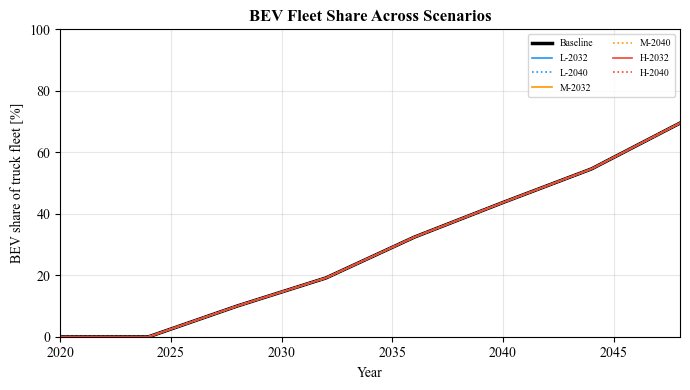

In [535]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, ax = plt.subplots(figsize=(7, 4))

for sc, info in SCENARIOS.items():
    h_data = all_h[sc]
    bev_share = []
    for y in YEARS_PLOT:
        icev = h_data.get(0, {}).get(y, 0)
        bev = h_data.get(1, {}).get(y, 0)
        total = icev + bev
        bev_share.append(bev / total * 100 if total > 0 else 0)
    lw = 2.5 if sc == 'DE_unified' else 1.2
    ax.plot(YEARS_PLOT, bev_share, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])

ax.set_xlabel('Year')
ax.set_ylabel('BEV share of truck fleet [%]')
ax.set_title('BEV Fleet Share Across Scenarios', fontweight='bold')
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlim(2020, 2048)
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_bev_fleet_share.pdf', bbox_inches='tight', dpi=300)
plt.show()

## RQ2: Charging Demand North vs South\nHow does the zone split redistribute charging energy between German zones?

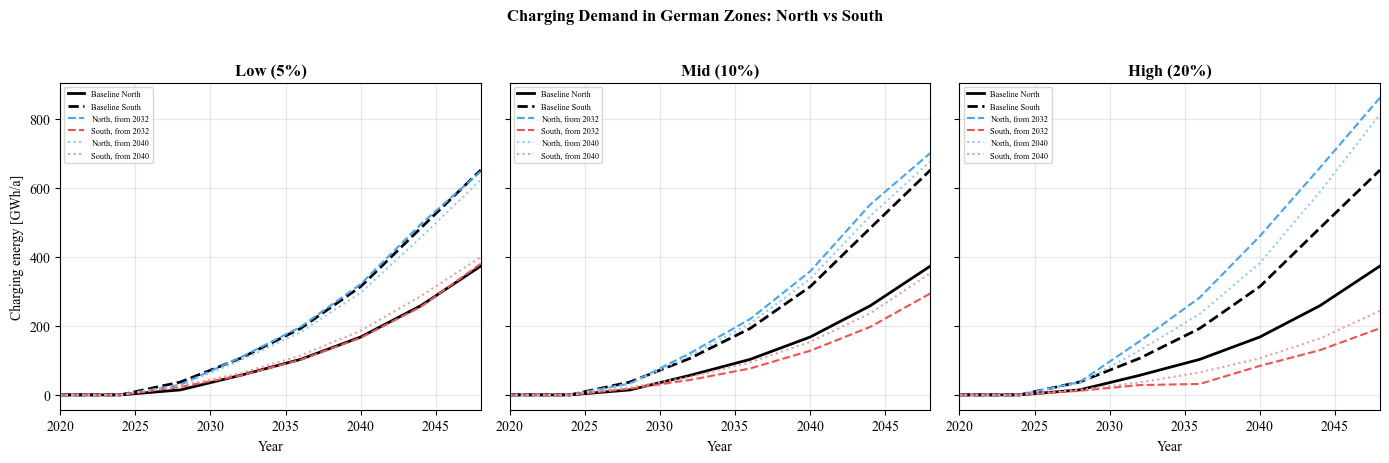

In [536]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]
spread_groups = [(5, 'Low (5%)'), (10, 'Mid (10%)'), (20, 'High (20%)')]
timing_colors_n = {2020: '#1565C0', 2032: '#42A5F5', 2040: '#90CAF9'}
timing_colors_s = {2020: '#C62828', 2032: '#EF5350', 2040: '#EF9A9A'}
timing_styles = {2020: '-', 2032: '--', 2040: ':'}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax_idx, (spread, spread_label) in enumerate(spread_groups):
    ax = axes[ax_idx]
    baseline_n = [all_s['DE_unified'].get('DE-North', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
    baseline_s = [all_s['DE_unified'].get('DE-South', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
    ax.plot(YEARS_PLOT, baseline_n, 'k-', lw=2, label='Baseline North')
    ax.plot(YEARS_PLOT, baseline_s, 'k--', lw=2, label='Baseline South')
    for sc, info in SCENARIOS.items():
        if info['spread'] != spread:
            continue
        timing = info['timing']
        north = [all_s[sc].get('DE-North', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
        south = [all_s[sc].get('DE-South', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
        ax.plot(YEARS_PLOT, north, color=timing_colors_n[timing], ls=timing_styles[timing], lw=1.5, label=f'North, from {timing}')
        ax.plot(YEARS_PLOT, south, color=timing_colors_s[timing], ls=timing_styles[timing], lw=1.5, label=f'South, from {timing}')
    ax.set_title(spread_label, fontweight='bold')
    ax.set_xlabel('Year')
    if ax_idx == 0:
        ax.set_ylabel('Charging energy [GWh/a]')
    ax.legend(fontsize=6, loc='upper left')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(2020, 2048)

fig.suptitle('Charging Demand in German Zones: North vs South', fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_charging_demand_north_south.pdf', bbox_inches='tight', dpi=300)
plt.show()

### Charging Demand Delta vs Baseline

<>:20: SyntaxWarning: invalid escape sequence '\D'
<>:20: SyntaxWarning: invalid escape sequence '\D'
C:\Users\simuser\AppData\Local\Temp\ipykernel_4244\1687931491.py:20: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel('$\Delta$ Charging [GWh/a]', fontsize=9)


  -> also saved to EEM: eem_charging_demand_delta.pdf


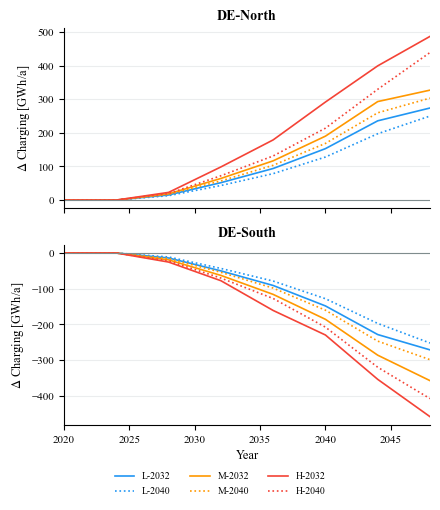

In [537]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, axes = plt.subplots(2, 1, figsize=(4.5, 5), sharex=True)

for zone_idx, zone in enumerate(['DE-North', 'DE-South']):
    ax = axes[zone_idx]
    baseline = {y: all_s['DE_unified'].get(zone, {}).get(y, 0) for y in YEARS_PLOT}
    for sc, info in SCENARIOS.items():
        if sc == 'DE_unified':
            continue
        delta = [(all_s[sc].get(zone, {}).get(y, 0) - baseline[y]) / 1e3 for y in YEARS_PLOT]
        ax.plot(YEARS_PLOT, delta, color=info['color'], ls=info['ls'], lw=1.2, label=info['label'])
    ax.axhline(0, color='#7F8C8D', lw=0.8)
    ax.set_title(zone, fontweight='bold', fontsize=10)
    ax.set_ylabel('$\Delta$ Charging [GWh/a]', fontsize=9)
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(2020, 2048)

axes[1].set_xlabel('Year', fontsize=9)

# Legend outside but closer to the subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=7, ncol=3, loc='lower center',
           bbox_to_anchor=(0.5, -0.02), frameon=False)

fig.tight_layout()
fig.subplots_adjust(bottom=0.14)
fig.savefig(FIGURES_DIR / 'eem_charging_demand_delta.pdf', bbox_inches='tight', dpi=300)
save_eem(fig, 'eem_charging_demand_delta.pdf')
plt.show()

mpl.rcParams['font.family'] = 'sans-serif'

### North Share of German Charging Demand

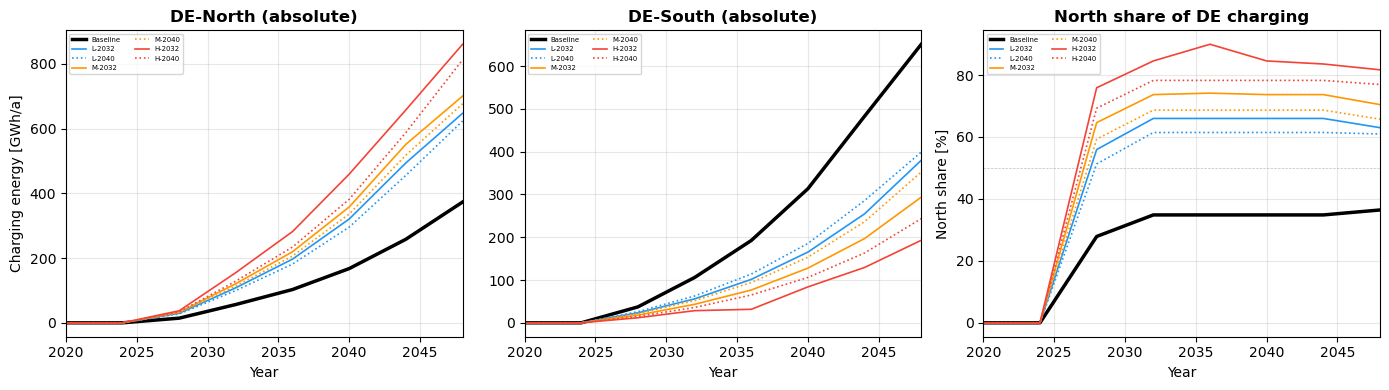

In [538]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Panel 1: Absolute North
ax = axes[0]
for sc, info in SCENARIOS.items():
    north = [all_s[sc].get('DE-North', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
    lw = 2.5 if sc == 'DE_unified' else 1.2
    ax.plot(YEARS_PLOT, north, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])
ax.set_xlabel('Year')
ax.set_ylabel('Charging energy [GWh/a]')
ax.set_title('DE-North (absolute)', fontweight='bold')
ax.legend(fontsize=5, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlim(2020, 2048)

# Panel 2: Absolute South
ax = axes[1]
for sc, info in SCENARIOS.items():
    south = [all_s[sc].get('DE-South', {}).get(y, 0) / 1e3 for y in YEARS_PLOT]
    lw = 2.5 if sc == 'DE_unified' else 1.2
    ax.plot(YEARS_PLOT, south, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])
ax.set_xlabel('Year')
ax.set_title('DE-South (absolute)', fontweight='bold')
ax.legend(fontsize=5, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlim(2020, 2048)

# Panel 3: North share
ax = axes[2]
for sc, info in SCENARIOS.items():
    north = [all_s[sc].get('DE-North', {}).get(y, 0) for y in YEARS_PLOT]
    south = [all_s[sc].get('DE-South', {}).get(y, 0) for y in YEARS_PLOT]
    total = [n + s for n, s in zip(north, south)]
    share = [n / t * 100 if t > 0 else 0 for n, t in zip(north, total)]
    lw = 2.5 if sc == 'DE_unified' else 1.2
    ax.plot(YEARS_PLOT, share, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])
ax.axhline(50, color='gray', lw=0.5, ls='--', alpha=0.5)
ax.set_xlabel('Year')
ax.set_ylabel('North share [%]')
ax.set_title('North share of DE charging', fontweight='bold')
ax.legend(fontsize=5, ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlim(2020, 2048)

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_charging_absolute_and_share.pdf', bbox_inches='tight', dpi=300)
plt.show()

## RQ3: Infrastructure Overcapacity from Timing\nDoes late splitting create stranded infrastructure in the South?

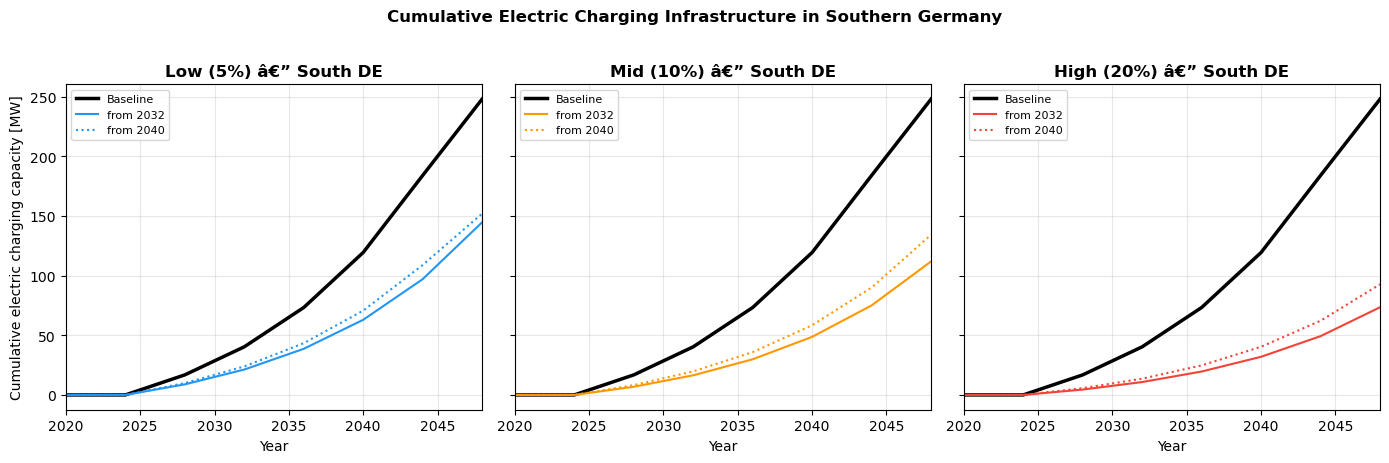

In [539]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax_idx, (spread, spread_label) in enumerate(spread_groups):
    ax = axes[ax_idx]
    for sc, info in SCENARIOS.items():
        if info['spread'] != spread and sc != 'DE_unified':
            continue
        cumul_south = []
        cumul = 0
        for y in YEARS_PLOT:
            cumul += all_q_elec[sc].get('DE-South', {}).get(y, 0)
            cumul_south.append(cumul / 1e3)  # kW -> MW
        lw = 2.5 if sc == 'DE_unified' else 1.5
        color = 'black' if sc == 'DE_unified' else info['color']
        ls = '-' if sc == 'DE_unified' else info['ls']
        label = 'Baseline' if sc == 'DE_unified' else f'from {info["timing"]}'
        ax.plot(YEARS_PLOT, cumul_south, color=color, ls=ls, lw=lw, label=label)
    ax.set_title(f'{spread_label} â€” South DE', fontweight='bold')
    ax.set_xlabel('Year')
    if ax_idx == 0:
        ax.set_ylabel('Cumulative electric charging capacity [MW]')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(2020, 2048)

fig.suptitle('Cumulative Electric Charging Infrastructure in Southern Germany', fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_infrastructure_south_cumulative.pdf', bbox_inches='tight', dpi=300)
plt.show()

### Stranded Capacity: South-DE Excess vs Early Split\nPositive = more South capacity than early-split scenario â†’ potentially underutilized.

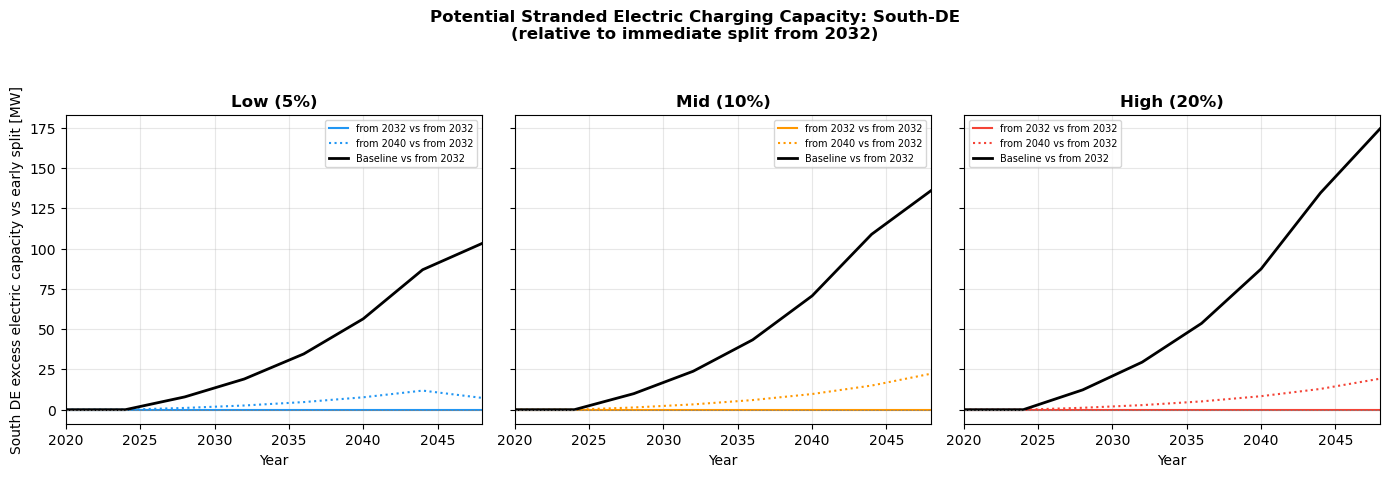

In [540]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax_idx, (spread, spread_label) in enumerate(spread_groups):
    ax = axes[ax_idx]
    level = {5: 'low', 10: 'mid', 20: 'high'}[spread]
    ref_sc = f'DE_split_{level}_from2032'

    for timing in [2032, 2040]:
        sc = f'DE_split_{level}_from{timing}'
        info = SCENARIOS[sc]
        cumul_sc, cumul_ref = 0, 0
        delta_list = []
        for y in YEARS_PLOT:
            cumul_sc += all_q_elec[sc].get('DE-South', {}).get(y, 0)
            cumul_ref += all_q_elec[ref_sc].get('DE-South', {}).get(y, 0)
            delta_list.append((cumul_sc - cumul_ref) / 1e3)
        ax.plot(YEARS_PLOT, delta_list, color=info['color'], ls=info['ls'], lw=1.5,
                label=f'from {timing} vs from 2032')

    cumul_base, cumul_ref = 0, 0
    delta_base = []
    for y in YEARS_PLOT:
        cumul_base += all_q_elec['DE_unified'].get('DE-South', {}).get(y, 0)
        cumul_ref += all_q_elec[ref_sc].get('DE-South', {}).get(y, 0)
        delta_base.append((cumul_base - cumul_ref) / 1e3)
    ax.plot(YEARS_PLOT, delta_base, 'k-', lw=2, label='Baseline vs from 2032')

    ax.axhline(0, color='gray', lw=0.5, ls='--')
    ax.set_title(spread_label, fontweight='bold')
    ax.set_xlabel('Year')
    if ax_idx == 0:
        ax.set_ylabel('South DE excess electric capacity vs early split [MW]')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(2020, 2048)

fig.suptitle('Potential Stranded Electric Charging Capacity: South-DE\n(relative to immediate split from 2032)',
             fontweight='bold', y=1.05)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_stranded_capacity_south.pdf', bbox_inches='tight', dpi=300)
plt.show()

### North Share of Charging Infrastructure

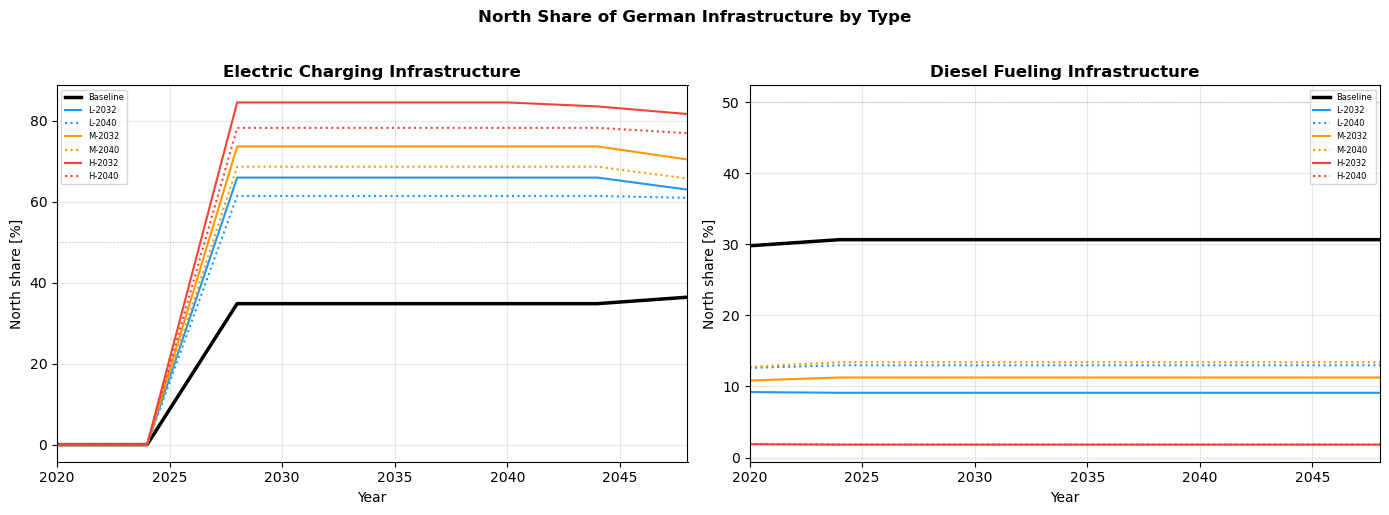

In [541]:
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax_idx, (q_data, q_label) in enumerate([
    (all_q_elec, 'Electric Charging Infrastructure'),
    (all_q_diesel, 'Diesel Fueling Infrastructure')
]):
    ax = axes[ax_idx]
    for sc, info in SCENARIOS.items():
        cumul_n, cumul_s = 0, 0
        share_list = []
        for y in YEARS_PLOT:
            cumul_n += q_data[sc].get('DE-North', {}).get(y, 0)
            cumul_s += q_data[sc].get('DE-South', {}).get(y, 0)
            total = cumul_n + cumul_s
            share_list.append(cumul_n / total * 100 if total > 0 else 0)
        lw = 2.5 if sc == 'DE_unified' else 1.5
        ax.plot(YEARS_PLOT, share_list, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])
    ax.axhline(50, color='gray', lw=0.5, ls='--', alpha=0.5)
    ax.set_xlabel('Year')
    ax.set_ylabel('North share [%]')
    ax.set_title(q_label, fontweight='bold')
    ax.legend(fontsize=6, loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(2020, 2048)

fig.suptitle('North Share of German Infrastructure by Type', fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_north_share_infrastructure.pdf', bbox_inches='tight', dpi=300)
plt.show()

### Absolute Difference in Installed Electric Charging Capacity vs Baseline
Bar plot showing cumulative capacity delta (North and South) at 2032 and 2048.

  -> also saved to EEM: eem_capacity_delta_bars.pdf


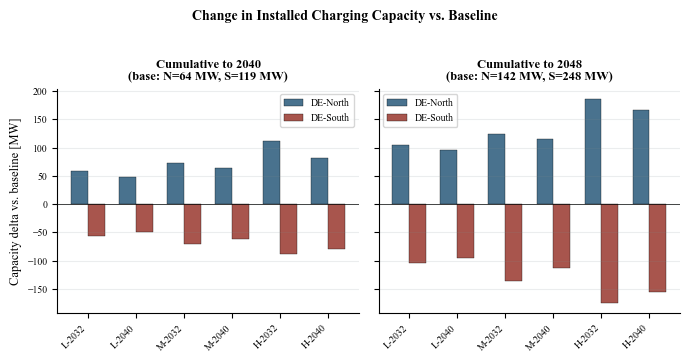


Scenario    2040 dN[MW]  2040 dS[MW]  2048 dN[MW]  2048 dS[MW]
------------------------------------------------------------
L-2032            +58.3       -56.4      +104.3      -103.2
L-2040            +48.8       -48.7       +95.2       -95.9
M-2032            +72.5       -70.7      +124.6      -136.0
M-2040            +64.2       -60.9      +115.5      -113.7
H-2032           +111.1       -87.4      +185.5      -174.4
H-2040            +81.5       -79.0      +167.2      -155.2

Stranded capacity indicator (late vs early split, South-DE):
Scenario         2040       2048  (positive = more South cap than early split)
----------------------------------------
L-2032          +0.0MW      +0.0MW
L-2040          +7.7MW      +7.3MW
M-2032          +0.0MW      +0.0MW
M-2040          +9.7MW     +22.3MW
H-2032          +0.0MW      +0.0MW
H-2040          +8.4MW     +19.2MW


In [542]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

# Infrastructure reallocation: cumulative installed capacity delta vs baseline
# q_fuel_infr_plus geo mapping is reliable (uses actual geo_ids).

sc_labels_short = {
    'DE_split_low_from2032': 'L-2032', 'DE_split_low_from2040': 'L-2040',
    'DE_split_mid_from2032': 'M-2032', 'DE_split_mid_from2040': 'M-2040',
    'DE_split_high_from2032': 'H-2032', 'DE_split_high_from2040': 'H-2040',
}
sc_order = list(sc_labels_short.keys())

def cumul_q_mw(q_data, zone, up_to_year):
    return sum(q_data.get(zone, {}).get(y, 0) for y in MODELED_YEARS if y <= up_to_year) / 1e3

# Bar plot: capacity delta vs baseline at 2040 and 2048
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True)
bar_width = 0.35
x = np.arange(len(sc_order))

for col, year in enumerate([2040, 2048]):
    ax = axes[col]
    base_n = cumul_q_mw(all_q_elec['DE_unified'], 'DE-North', year)
    base_s = cumul_q_mw(all_q_elec['DE_unified'], 'DE-South', year)

    delta_n = [cumul_q_mw(all_q_elec[sc], 'DE-North', year) - base_n for sc in sc_order]
    delta_s = [cumul_q_mw(all_q_elec[sc], 'DE-South', year) - base_s for sc in sc_order]

    ax.bar(x - bar_width/2, delta_n, bar_width, color='#1B4F72', edgecolor='black',
           linewidth=0.3, alpha=0.8, label='DE-North')
    ax.bar(x + bar_width/2, delta_s, bar_width, color='#922B21', edgecolor='black',
           linewidth=0.3, alpha=0.8, label='DE-South')

    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'Cumulative to {year}\n(base: N={base_n:.0f} MW, S={base_s:.0f} MW)',
                 fontsize=9, fontweight='bold')
    if col == 0:
        ax.set_ylabel('Capacity delta vs. baseline [MW]', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks(x)
    ax.set_xticklabels([sc_labels_short[sc] for sc in sc_order],
                       rotation=45, ha='right', fontsize=7)

fig.suptitle('Change in Installed Charging Capacity vs. Baseline',
             fontweight='bold', fontsize=10, y=1.02)
fig.tight_layout()
save_eem(fig, 'eem_capacity_delta_bars.pdf')
plt.show()

mpl.rcParams['font.family'] = 'sans-serif'

# Print table
print(f"\n{'Scenario':<10} {'2040 dN[MW]':>12} {'2040 dS[MW]':>12} {'2048 dN[MW]':>12} {'2048 dS[MW]':>12}")
print("-" * 60)
for sc in sc_order:
    vals = []
    for year in [2040, 2048]:
        base_n = cumul_q_mw(all_q_elec['DE_unified'], 'DE-North', year)
        base_s = cumul_q_mw(all_q_elec['DE_unified'], 'DE-South', year)
        dn = cumul_q_mw(all_q_elec[sc], 'DE-North', year) - base_n
        ds = cumul_q_mw(all_q_elec[sc], 'DE-South', year) - base_s
        vals.extend([f"{dn:>+12.1f}", f"{ds:>+12.1f}"])
    print(f"{sc_labels_short[sc]:<10} {''.join(vals)}")

# Stranded capacity interpretation
print("\nStranded capacity indicator (late vs early split, South-DE):")
print(f"{'Scenario':<10} {'2040':>10} {'2048':>10}  (positive = more South cap than early split)")
print("-" * 40)
for level, ref in [('low', 'DE_split_low_from2032'), ('mid', 'DE_split_mid_from2032'), ('high', 'DE_split_high_from2032')]:
    for timing in [2032, 2040]:
        sc = f'DE_split_{level}_from{timing}'
        line = f"{sc_labels_short[sc]:<10}"
        for year in [2040, 2048]:
            sc_cap = cumul_q_mw(all_q_elec[sc], 'DE-South', year)
            ref_cap = cumul_q_mw(all_q_elec[ref], 'DE-South', year)
            line += f" {sc_cap - ref_cap:>+9.1f}MW"
        print(line)

### Charging Demand by Country/Zone
Breakdown of total BEV charging energy by country and German zone for all scenarios at 2040.

In [543]:
# Charging demand by country/zone at 2040 for all scenarios
zones_order = ['DE-North', 'DE-South', 'AT', 'IT', 'SE', 'Other']

print(f"{'Scenario':<35}", end="")
for z in zones_order:
    print(f" {z:>9}", end="")
print(f" {'Total':>9}")
print("-" * (35 + 10 * (len(zones_order) + 1)))

for sc, info in SCENARIOS.items():
    s_data = all_s[sc]
    row = {}
    for zone, ydict in s_data.items():
        val = ydict.get(2040, 0) / 1e3  # MWh -> GWh
        # Group non-DE/AT/IT/SE into 'Other'
        if zone not in ('DE-North', 'DE-South') and zone not in ('AT', 'IT', 'SE'):
            row['Other'] = row.get('Other', 0) + val
        else:
            row[zone] = row.get(zone, 0) + val
    total = sum(row.values())
    print(f"{info['label']:<35}", end="")
    for z in zones_order:
        print(f" {row.get(z, 0):>9.1f}", end="")
    print(f" {total:>9.1f}")

# Show percentage shares for baseline vs high-from-2020
print("\n\nPercentage shares at 2040:")
for sc_name in ['DE_unified', 'DE_split_high_from2032']:
    info = SCENARIOS[sc_name]
    s_data = all_s[sc_name]
    row = {}
    for zone, ydict in s_data.items():
        val = ydict.get(2040, 0) / 1e3
        if zone not in ('DE-North', 'DE-South') and zone not in ('AT', 'IT', 'SE'):
            row['Other'] = row.get('Other', 0) + val
        else:
            row[zone] = row.get(zone, 0) + val
    total = sum(row.values())
    print(f"{info['label']:<35}", end="")
    for z in zones_order:
        pct = row.get(z, 0) / total * 100 if total > 0 else 0
        print(f" {pct:>8.1f}%", end="")
    print()

Scenario                             DE-North  DE-South        AT        IT        SE     Other     Total
---------------------------------------------------------------------------------------------------------
Baseline                                167.6     313.6     525.2     415.0      39.9       8.5    1469.8
L-2032                                  320.8     165.4     527.5     410.0      35.9      10.2    1469.8
L-2040                                  295.8     185.6     527.1     414.7      37.6       8.9    1469.8
M-2032                                  358.0     127.9     530.1     410.3      32.9      10.6    1469.8
M-2040                                  336.3     153.4     530.6     406.4      34.1       8.9    1469.8
H-2032                                  459.6      84.0     444.5     445.3      27.4       9.0    1469.8
H-2040                                  381.7     106.0     535.1     408.5      27.6      10.9    1469.8


Percentage shares at 2040:
Baseline         

## Transport Performance by Technology and Zone (RQ1b)
How does the zone split affect the BEV vs ICEV split of transport performance (tkm) in North vs South Germany?

Based on `f` (flow in tonnes) Ã— path distance through each zone.

In [544]:
# ---- Build path km in each German zone ----
_paths_data = yaml.load(open(INPUT_DIR / 'DE_unified' / 'Path.yaml'), Loader=yaml.UnsafeLoader)

path_km_by_zone = {}  # path_id -> {'DE-North': km, 'DE-South': km}
for p in _paths_data:
    pid = p['id']
    seq = p['sequence']
    dist = p['distance_from_previous']
    zkm = {'DE-North': 0.0, 'DE-South': 0.0}
    for i in range(1, len(seq)):
        d = dist[i]
        z_from = geo_id_to_zone.get(seq[i-1], 'Other')
        z_to = geo_id_to_zone.get(seq[i], 'Other')
        for z in [z_from, z_to]:
            if z in zkm:
                zkm[z] += d / 2.0
    path_km_by_zone[pid] = zkm

# ---- Parse f variable ----
PAT_F = re.compile(r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)')

def load_tkm_by_zone_tech(scenario, target_years={2032, 2040}):
    """Load transport performance (tkm) by zone and technology.
    f key: (year, (product, odpair_id, path_id), (mode_id, tv_id), generation)
    f value: tonnes transported.
    tkm = f * km_in_zone."""
    fpath = list((RESULTS_DIR / scenario).glob('*_f_dict.yaml'))
    if not fpath:
        return {}
    result = defaultdict(lambda: defaultdict(lambda: defaultdict(float)))
    with open(fpath[-1], 'r') as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            sep = line.rfind(': ')
            if sep < 0:
                continue
            m = PAT_F.match(line[:sep])
            if not m:
                continue
            year = int(m.group(1))
            if year not in target_years:
                continue
            path_id = int(m.group(4))
            tv_id = int(m.group(6))
            val = float(line[sep+2:])
            tech = 'BEV' if tv_id == 1 else 'ICEV'
            result[year]['DE-North'][tech] += val * path_km_by_zone.get(path_id, {}).get('DE-North', 0)
            result[year]['DE-South'][tech] += val * path_km_by_zone.get(path_id, {}).get('DE-South', 0)
    return result

# Load for all scenarios
all_tkm = {}
for sc in SCENARIOS:
    all_tkm[sc] = load_tkm_by_zone_tech(sc)
    print(f"  Loaded tkm for {sc}")
print("Done.")

  Loaded tkm for DE_unified
  Loaded tkm for DE_split_low_from2032
  Loaded tkm for DE_split_low_from2040
  Loaded tkm for DE_split_mid_from2032
  Loaded tkm for DE_split_mid_from2040
  Loaded tkm for DE_split_high_from2032
  Loaded tkm for DE_split_high_from2040
Done.


  -> also saved to EEM: eem_tkm_stacked.pdf


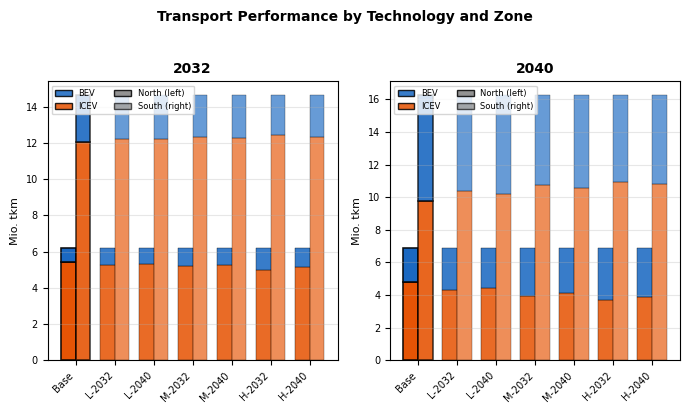


Scenario   2032 N_BEV% 2032 S_BEV% 2040 N_BEV% 2040 S_BEV%
------------------------------------------------------------
Base             12.3%      17.8%      30.0%      40.0%
L-2032           14.7%      16.6%      37.7%      36.2%
L-2040           14.2%      16.8%      35.4%      37.2%
M-2032           15.8%      16.1%      42.3%      34.1%
M-2040           15.3%      16.4%      40.3%      35.1%
H-2032           19.4%      15.2%      46.2%      32.8%
H-2040           16.5%      15.9%      43.5%      33.5%


In [545]:
# Plot (1): Stacked BEV + ICEV transport performance by scenario and year
# Paired bars: North and South side-by-side for each scenario

sc_labels_short_with_base = {
    'DE_unified': 'Base',
    'DE_split_low_from2032': 'L-2032', 'DE_split_low_from2040': 'L-2040',
    'DE_split_mid_from2032': 'M-2032', 'DE_split_mid_from2040': 'M-2040',
    'DE_split_high_from2032': 'H-2032', 'DE_split_high_from2040': 'H-2040',
}
sc_order_with_base = list(sc_labels_short_with_base.keys())

def get_tkm(data, year, zone, tech):
    return data.get(year, {}).get(zone, {}).get(tech, 0)

fig, axes = plt.subplots(1, 2, figsize=(7, 4))
bar_width = 0.38
group_width = 1.0
x = np.arange(len(sc_order_with_base)) * group_width

for col, year in enumerate([2032, 2040]):
    ax = axes[col]

    for side, (zone, offset, alpha) in enumerate([
        ('DE-North', -bar_width/2, 0.85),
        ('DE-South', +bar_width/2, 0.65),
    ]):
        bev_vals = [get_tkm(all_tkm[sc], year, zone, 'BEV') / 1e6 for sc in sc_order_with_base]
        icev_vals = [get_tkm(all_tkm[sc], year, zone, 'ICEV') / 1e6 for sc in sc_order_with_base]

        # Stacked: ICEV on bottom, BEV on top
        ax.bar(x + offset, icev_vals, bar_width, color='#E65100', edgecolor='black',
               linewidth=0.3, alpha=alpha, label='ICEV' if side == 0 else None)
        ax.bar(x + offset, bev_vals, bar_width, bottom=icev_vals, color='#1565C0',
               edgecolor='black', linewidth=0.3, alpha=alpha, label='BEV' if side == 0 else None)

        # Highlight baseline with thicker border
        ax.bar(x[0:1] + offset, [icev_vals[0]], bar_width, color='#E65100', edgecolor='black',
               linewidth=1.2, alpha=alpha)
        ax.bar(x[0:1] + offset, [bev_vals[0]], bar_width, bottom=[icev_vals[0]], color='#1565C0',
               edgecolor='black', linewidth=1.2, alpha=alpha)

    # Add zone labels in legend via invisible patches
    from matplotlib.patches import Patch
    handles = [
        Patch(facecolor='#1565C0', edgecolor='black', alpha=0.85, label='BEV'),
        Patch(facecolor='#E65100', edgecolor='black', alpha=0.85, label='ICEV'),
        Patch(facecolor='gray', edgecolor='black', alpha=0.85, label='North (left)'),
        Patch(facecolor='gray', edgecolor='black', alpha=0.65, label='South (right)'),
    ]
    ax.legend(handles=handles, fontsize=6, loc='upper left', ncol=2)

    ax.set_title(f'{year}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mio. tkm', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([sc_labels_short_with_base[sc] for sc in sc_order_with_base],
                       rotation=45, ha='right', fontsize=7)
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(labelsize=7)

fig.suptitle('Transport Performance by Technology and Zone', fontweight='bold', fontsize=10, y=1.02)
fig.tight_layout()
save_eem(fig, 'eem_tkm_stacked.pdf')
plt.show()

# Print BEV share summary
print(f"\n{'Scenario':<10} {'2032 N_BEV%':>11} {'2032 S_BEV%':>11} {'2040 N_BEV%':>11} {'2040 S_BEV%':>11}")
print("-" * 60)
for sc in sc_order_with_base:
    vals = []
    for year in [2032, 2040]:
        for zone in ['DE-North', 'DE-South']:
            bev = get_tkm(all_tkm[sc], year, zone, 'BEV')
            icev = get_tkm(all_tkm[sc], year, zone, 'ICEV')
            total = bev + icev
            pct = bev / total * 100 if total > 0 else 0
            vals.append(f"{pct:>10.1f}%")
    print(f"{sc_labels_short_with_base[sc]:<10} {''.join(vals)}")

  -> also saved to EEM: eem_route_bev_violin.pdf


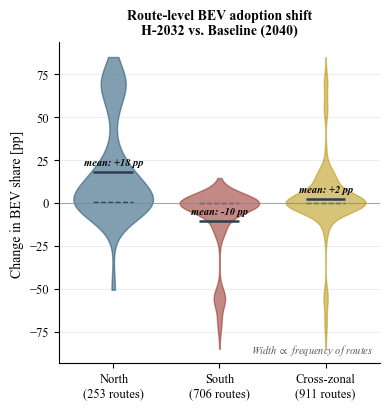

North only: 253 routes, mean +18.0pp, median +0.7pp, 123 gained >5pp, 20 lost >5pp
South only: 706 routes, mean -10.4pp, median -0.0pp, 7 gained >5pp, 189 lost >5pp
Cross-zonal: 911 routes, mean +2.2pp, median +0.1pp, 212 gained >5pp, 95 lost >5pp


In [546]:
# Route-level BEV share change: Violin plot by corridor type
# Baseline vs H-2032 at 2040

import yaml as _yaml
from collections import defaultdict as _dd
import matplotlib as mpl

# Set Times-like font
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

# Build path -> zone classification
_paths_data2 = _yaml.load(open(INPUT_DIR / 'DE_unified' / 'Path.yaml'), Loader=_yaml.UnsafeLoader)
_path_zones = {}
for p in _paths_data2:
    zones_on_path = [geo_id_to_zone.get(g, '??') for g in p['sequence']]
    has_n = 'DE-North' in zones_on_path
    has_s = 'DE-South' in zones_on_path
    if has_n and has_s:
        _path_zones[p['id']] = 'Cross-zonal'
    elif has_n:
        _path_zones[p['id']] = 'North only'
    elif has_s:
        _path_zones[p['id']] = 'South only'
    else:
        _path_zones[p['id']] = 'Non-DE'

_odpairs2 = _yaml.load(open(INPUT_DIR / 'DE_unified' / 'Odpair.yaml'), Loader=_yaml.UnsafeLoader)
_od_to_path2 = {od['id']: od['path_id'] for od in _odpairs2}

# Load f at 2040 — auto-detect old (CartesianIndex) vs new (tuple) format
PAT_F_OLD = re.compile(r'\((\d+),\s*\((\d+),\s*(\d+),\s*(\d+)\),\s*\((\d+),\s*(\d+)\),\s*(\d+)\)')
PAT_F_NEW = re.compile(r'\((\d+),\s*\(\d+,\s*(\d+),\s*\d+\),\s*\(\d+,\s*(\d+)\),\s*\d+\)')

def _load_f_by_od(scenario, year=2040):
    fpath = sorted((RESULTS_DIR / scenario).glob('*_f_dict.yaml'))[-1]
    fmt = _detect_format(fpath)
    result = _dd(lambda: {'BEV': 0.0, 'ICEV': 0.0})
    with open(fpath) as fh:
        for line in fh:
            line = line.strip()
            if not line: continue
            sep = line.rfind(': ')
            if sep < 0: continue
            if fmt == 'tuple':
                m = PAT_F_NEW.match(line[:sep])
                if not m: continue
                if int(m.group(1)) != year: continue
                odpair_id = int(m.group(2))
                tv_id = int(m.group(3))
                val = float(line[sep+2:])
                result[odpair_id]['BEV' if tv_id == 1 else 'ICEV'] += val
            else:
                m = PAT_F_OLD.match(line[:sep])
                if not m: continue
                if int(m.group(1)) != year: continue
                odpair_id = int(m.group(3))
                tv_id = int(m.group(6))
                val = float(line[sep+2:])
                result[odpair_id]['BEV' if tv_id == 1 else 'ICEV'] += val
    return result

f_base = _load_f_by_od('DE_unified')
f_h2032 = _load_f_by_od('DE_split_high_from2032')

# Compute deltas by corridor type
deltas = {'North only': [], 'South only': [], 'Cross-zonal': []}
for od in sorted(set(f_base.keys()) | set(f_h2032.keys())):
    b, h = f_base[od], f_h2032[od]
    bt, ht = b['BEV'] + b['ICEV'], h['BEV'] + h['ICEV']
    if bt < 1 and ht < 1: continue
    bs = b['BEV'] / bt * 100 if bt > 0 else 0
    hs = h['BEV'] / ht * 100 if ht > 0 else 0
    pid = _od_to_path2.get(od)
    cat = _path_zones.get(pid, 'Non-DE')
    if cat in deltas:
        deltas[cat].append(hs - bs)

# Colors: muted academic palette
col_north = '#1B4F72'   # deep steel blue
col_south = '#922B21'   # muted burgundy
col_cross = '#B7950B'   # dark gold

# Plot
fig, ax = plt.subplots(figsize=(4, 4.2))

cats = ['North only', 'South only', 'Cross-zonal']
colors = [col_north, col_south, col_cross]
data = [deltas[c] for c in cats]

parts = ax.violinplot(data, positions=[1, 2, 3], showmeans=True, showmedians=True,
                      showextrema=False, widths=0.75)

for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.55)
    pc.set_edgecolor(colors[i])
    pc.set_linewidth(1.0)

parts['cmeans'].set_color('#2C3E50')
parts['cmeans'].set_linewidth(1.8)
parts['cmeans'].set_linestyle('-')
parts['cmedians'].set_color('#2C3E50')
parts['cmedians'].set_linestyle('--')
parts['cmedians'].set_linewidth(1.0)

ax.axhline(0, color='#7F8C8D', lw=0.8, ls='-', alpha=0.7)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels([f'North\n({len(deltas["North only"])} routes)',
                     f'South\n({len(deltas["South only"])} routes)',
                     f'Cross-zonal\n({len(deltas["Cross-zonal"])} routes)'],
                    fontsize=9)
ax.set_ylabel('Change in BEV share [pp]', fontsize=10)
ax.set_title('Route-level BEV adoption shift\nH-2032 vs. Baseline (2040)',
             fontweight='bold', fontsize=10)
ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
ax.tick_params(labelsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Annotate means in black
for i, cat in enumerate(cats):
    m = np.mean(deltas[cat])
    ax.text(i + 1, m + 4, f'mean: {m:+.0f} pp', ha='center', fontsize=7.5,
            fontstyle='italic', color='black', fontweight='bold')

# Width annotation
ax.text(0.98, 0.02, r'Width $\propto$ frequency of routes',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=7.5, fontstyle='italic', color='#555555')

fig.tight_layout()
save_eem(fig, 'eem_route_bev_violin.pdf')
plt.show()

# Reset font to default for other cells
mpl.rcParams['font.family'] = 'sans-serif'

for cat in cats:
    d = deltas[cat]
    gained = sum(1 for x in d if x > 5)
    lost = sum(1 for x in d if x < -5)
    print(f"{cat}: {len(d)} routes, mean {np.mean(d):+.1f}pp, "
          f"median {np.median(d):+.1f}pp, {gained} gained >5pp, {lost} lost >5pp")

## Overcapacity Analysis (RQ3)

Now that `s` geo-attribution is corrected, we can quantify **infrastructure overcapacity** properly.

**Approach**: Compare each scenario's cumulative installed electric charging capacity against the capacity actually *needed* by the charging demand in that year. The model constraint is:

$$\text{installed\_kW} \geq \frac{1}{\gamma \cdot 8760} \cdot s \cdot 1000$$

where $\gamma = 0.3$ and $s$ is in MWh. So required capacity = $s \cdot 1000 / (0.3 \cdot 8760)$ kW.

Three perspectives:
1. **Utilization rate** = required / installed (closer to 1 = efficient, lower = overcapacity)
2. **Stranded capacity** = capacity installed in late-split scenario minus capacity in early-split, at same year
3. **Excess vs demand**: capacity installed under unified pricing that exceeds what the split scenario needs

In [547]:
# ---- Load s by zone and year (already in all_s as MWh) ----
# ---- Load q_elec by zone and year (already in all_q_elec as kW additions) ----

GAMMA = 0.3
HOURS_PER_YEAR = 8760
YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

# Also load initial fuel infrastructure (only diesel exists, no initial electric)
import yaml as _y
_init_infr = _y.safe_load(open(INPUT_DIR / 'DE_unified' / 'InitialFuelInfr.yaml'))
# Confirm: no electric initial infra
_elec_init = [i for i in _init_infr if 'elec' in str(i.get('fuel','')).lower()]
print(f"Initial electric infrastructure entries: {len(_elec_init)}")
print("-> All electric capacity comes from q_fuel_infr_plus additions\n")

def compute_overcapacity(sc, zone):
    """For a given scenario and zone, compute:
    - cumulative installed electric capacity [MW]
    - required capacity from s [MW]
    - overcapacity [MW] and utilization [%]
    """
    cumul_kw = 0
    results = []
    for y in YEARS_PLOT:
        cumul_kw += all_q_elec[sc].get(zone, {}).get(y, 0)  # kW added this period
        s_mwh = all_s[sc].get(zone, {}).get(y, 0)            # MWh consumed
        required_kw = s_mwh * 1000 / (GAMMA * HOURS_PER_YEAR)  # kW needed
        installed_mw = cumul_kw / 1e3
        required_mw = required_kw / 1e3
        overcap_mw = installed_mw - required_mw
        util = required_mw / installed_mw * 100 if installed_mw > 0 else 0
        results.append({
            'year': y, 'installed_mw': installed_mw, 'required_mw': required_mw,
            'overcap_mw': overcap_mw, 'utilization_pct': util
        })
    return results

# ---- Print summary table ----
print(f"{'Scenario':<25} {'Zone':<10} {'Year':>5} {'Installed':>10} {'Required':>10} {'Overcap':>10} {'Util%':>7}")
print(f"{'':25} {'':10} {'':5} {'[MW]':>10} {'[MW]':>10} {'[MW]':>10} {'':>7}")
print("-" * 82)

for sc_name in ['DE_unified', 'DE_split_high_from2032', 'DE_split_high_from2032', 'DE_split_high_from2040']:
    label = SCENARIOS[sc_name]['label']
    for zone in ['DE-North', 'DE-South']:
        data = compute_overcapacity(sc_name, zone)
        for d in data:
            if d['year'] in [2032, 2040, 2048]:
                print(f"{label:<25} {zone:<10} {d['year']:>5} {d['installed_mw']:>10.1f} {d['required_mw']:>10.1f} "
                      f"{d['overcap_mw']:>10.1f} {d['utilization_pct']:>6.1f}%")
    print()

# ---- Cross-scenario overcapacity: if baseline infra meets split-scenario demand ----
print("\n\n=== Cross-scenario overcapacity ===")
print("If infrastructure was built under unified pricing (baseline),")
print("how much would be underutilized when the split takes effect?\n")
print(f"{'Split scenario':<25} {'Zone':<10} {'Year':>5} {'Base inst':>10} {'Split req':>10} {'Excess':>10} {'Excess%':>8}")
print("-" * 83)

for sc_name in ['DE_split_low_from2032', 'DE_split_mid_from2032', 'DE_split_high_from2032',
                'DE_split_high_from2032', 'DE_split_high_from2040']:
    label = SCENARIOS[sc_name]['label']
    for zone in ['DE-North', 'DE-South']:
        base_data = compute_overcapacity('DE_unified', zone)
        split_data = compute_overcapacity(sc_name, zone)
        for bd, sd in zip(base_data, split_data):
            if bd['year'] in [2032, 2040, 2048]:
                excess = bd['installed_mw'] - sd['required_mw']
                excess_pct = excess / bd['installed_mw'] * 100 if bd['installed_mw'] > 0 else 0
                print(f"{label:<25} {zone:<10} {bd['year']:>5} {bd['installed_mw']:>10.1f} {sd['required_mw']:>10.1f} "
                      f"{excess:>10.1f} {excess_pct:>7.1f}%")
    print()

Initial electric infrastructure entries: 0
-> All electric capacity comes from q_fuel_infr_plus additions

Scenario                  Zone        Year  Installed   Required    Overcap   Util%
                                                 [MW]       [MW]       [MW]        
----------------------------------------------------------------------------------
Baseline                  DE-North    2032       21.5       21.5        0.0  100.0%
Baseline                  DE-North    2040       63.8       63.8        0.0  100.0%
Baseline                  DE-North    2048      142.0      142.0        0.0  100.0%
Baseline                  DE-South    2032       40.3       40.3        0.0  100.0%
Baseline                  DE-South    2040      119.3      119.3        0.0  100.0%
Baseline                  DE-South    2048      247.8      247.8        0.0  100.0%

H-2032                    DE-North    2032       59.1       59.1        0.0  100.0%
H-2032                    DE-North    2040      174.9

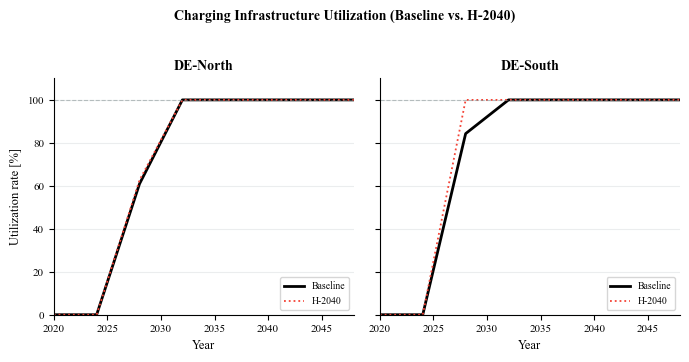

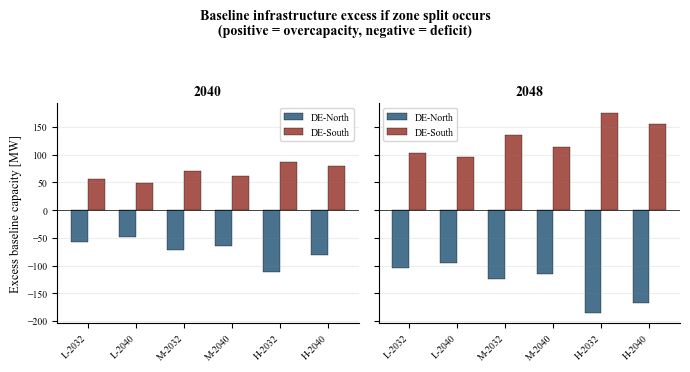


South-DE: Baseline infrastructure excess vs split-scenario demand at 2040:
Scenario                  Base inst [MW] Split req [MW]  Excess [MW]  Excess %
----------------------------------------------------------------------------
L-2032                             119.3           62.9         56.4     47.3%
L-2040                             119.3           70.6         48.7     40.8%
M-2032                             119.3           48.7         70.7     59.2%
M-2040                             119.3           58.4         60.9     51.1%
H-2032                             119.3           32.0         87.4     73.2%
H-2040                             119.3           40.3         79.0     66.2%


In [548]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

# ---- Figure 1: Utilization rate — baseline vs H-2040 only ----
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True)

for col, zone in enumerate(['DE-North', 'DE-South']):
    ax = axes[col]
    for sc_name in ['DE_unified', 'DE_split_high_from2040']:
        info = SCENARIOS[sc_name]
        data = compute_overcapacity(sc_name, zone)
        util = [d['utilization_pct'] for d in data]
        lw = 2.0 if sc_name == 'DE_unified' else 1.3
        ax.plot(YEARS_PLOT, util, color=info['color'], ls=info['ls'], lw=lw, label=info['label'])
    ax.axhline(100, color='#7F8C8D', lw=0.8, ls='--', alpha=0.5)
    ax.set_title(zone, fontweight='bold', fontsize=10)
    ax.set_xlabel('Year', fontsize=9)
    if col == 0:
        ax.set_ylabel('Utilization rate [%]', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(2020, 2048)
    ax.set_ylim(0, 110)

fig.suptitle('Charging Infrastructure Utilization (Baseline vs. H-2040)', fontweight='bold', fontsize=10, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_utilization_rate.pdf', bbox_inches='tight', dpi=300)
plt.show()

# ---- Figure 2: Cross-scenario overcapacity bar chart ----
# "What if we build baseline infrastructure but the split happens?"
# Excess = baseline_installed - split_required  (in South, positive = stranded)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharey=True)

sc_split_order = [
    'DE_split_low_from2032', 'DE_split_low_from2040',
    'DE_split_mid_from2032', 'DE_split_mid_from2040',
    'DE_split_high_from2032', 'DE_split_high_from2040',
]
sc_short = {
    'DE_split_low_from2032': 'L-2032', 'DE_split_low_from2040': 'L-2040',
    'DE_split_mid_from2032': 'M-2032', 'DE_split_mid_from2040': 'M-2040',
    'DE_split_high_from2032': 'H-2032', 'DE_split_high_from2040': 'H-2040',
}
x = np.arange(len(sc_split_order))
bar_width = 0.35

for col, year in enumerate([2040, 2048]):
    ax = axes[col]
    
    # For each split scenario: excess = baseline_installed - split_required
    excess_n, excess_s = [], []
    for sc in sc_split_order:
        base_n_data = compute_overcapacity('DE_unified', 'DE-North')
        base_s_data = compute_overcapacity('DE_unified', 'DE-South')
        split_n_data = compute_overcapacity(sc, 'DE-North')
        split_s_data = compute_overcapacity(sc, 'DE-South')
        
        yi = next(i for i, d in enumerate(base_n_data) if d['year'] == year)
        excess_n.append(base_n_data[yi]['installed_mw'] - split_n_data[yi]['required_mw'])
        excess_s.append(base_s_data[yi]['installed_mw'] - split_s_data[yi]['required_mw'])
    
    ax.bar(x - bar_width/2, excess_n, bar_width, color='#1B4F72', edgecolor='black',
           linewidth=0.3, alpha=0.8, label='DE-North')
    ax.bar(x + bar_width/2, excess_s, bar_width, color='#922B21', edgecolor='black',
           linewidth=0.3, alpha=0.8, label='DE-South')
    
    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'{year}', fontweight='bold', fontsize=10)
    if col == 0:
        ax.set_ylabel('Excess baseline capacity [MW]', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=7)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks(x)
    ax.set_xticklabels([sc_short[sc] for sc in sc_split_order], rotation=45, ha='right', fontsize=7)

fig.suptitle('Baseline infrastructure excess if zone split occurs\n(positive = overcapacity, negative = deficit)',
             fontweight='bold', fontsize=10, y=1.05)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_overcapacity_cross_scenario.pdf', bbox_inches='tight', dpi=300)
plt.show()

mpl.rcParams['font.family'] = 'sans-serif'

# ---- Summary: South-DE overcapacity at 2040 ----
print("\nSouth-DE: Baseline infrastructure excess vs split-scenario demand at 2040:")
print(f"{'Scenario':<25} {'Base inst [MW]':>14} {'Split req [MW]':>14} {'Excess [MW]':>12} {'Excess %':>9}")
print("-" * 76)
base_s = compute_overcapacity('DE_unified', 'DE-South')
yi_40 = next(i for i, d in enumerate(base_s) if d['year'] == 2040)
for sc in sc_split_order:
    split_s = compute_overcapacity(sc, 'DE-South')
    excess = base_s[yi_40]['installed_mw'] - split_s[yi_40]['required_mw']
    excess_pct = excess / base_s[yi_40]['installed_mw'] * 100 if base_s[yi_40]['installed_mw'] > 0 else 0
    print(f"{SCENARIOS[sc]['label']:<25} {base_s[yi_40]['installed_mw']:>14.1f} {split_s[yi_40]['required_mw']:>14.1f} "
          f"{excess:>12.1f} {excess_pct:>8.1f}%")

In [549]:
# ---- North-DE deficit: baseline infrastructure vs split-scenario demand ----
# If infrastructure was built under unified pricing, how much ADDITIONAL capacity
# would North-DE need if the split happens?

print("North-DE: Baseline infrastructure DEFICIT vs split-scenario demand")
print("\n(negative excess = deficit = additional capacity needed)\n")
print(f"{'Scenario':<25} {'Base inst [MW]':>14} {'Split req [MW]':>14} {'Deficit [MW]':>12} {'Deficit %':>10}")
print("-" * 78)

base_n = compute_overcapacity('DE_unified', 'DE-North')
yi_32 = next(i for i, d in enumerate(base_n) if d['year'] == 2032)
yi_40 = next(i for i, d in enumerate(base_n) if d['year'] == 2040)
yi_48 = next(i for i, d in enumerate(base_n) if d['year'] == 2048)

for year_label, yi in [('2032', yi_32), ('2040', yi_40), ('2048', yi_48)]:
    print(f"\n  --- Year {year_label} ---")
    for sc in sc_split_order:
        split_n = compute_overcapacity(sc, 'DE-North')
        deficit = split_n[yi]['required_mw'] - base_n[yi]['installed_mw']
        deficit_pct = deficit / split_n[yi]['required_mw'] * 100 if split_n[yi]['required_mw'] > 0 else 0
        print(f"{SCENARIOS[sc]['label']:<25} {base_n[yi]['installed_mw']:>14.1f} {split_n[yi]['required_mw']:>14.1f} "
              f"{deficit:>12.1f} {deficit_pct:>9.1f}%")

# ---- Combined view: South overcapacity + North deficit at 2040 ----
print("\n\n" + "="*85)
print("COMBINED VIEW at 2040: South stranded capacity + North infrastructure deficit")
print("="*85)
print(f"{'Scenario':<25} {'S excess [MW]':>13} {'S excess %':>10} {'N deficit [MW]':>14} {'N deficit %':>11}")
print("-" * 75)

base_s_data = compute_overcapacity('DE_unified', 'DE-South')
base_n_data = compute_overcapacity('DE_unified', 'DE-North')

for sc in sc_split_order:
    split_s = compute_overcapacity(sc, 'DE-South')
    split_n = compute_overcapacity(sc, 'DE-North')
    
    s_excess = base_s_data[yi_40]['installed_mw'] - split_s[yi_40]['required_mw']
    s_excess_pct = s_excess / base_s_data[yi_40]['installed_mw'] * 100 if base_s_data[yi_40]['installed_mw'] > 0 else 0
    
    n_deficit = split_n[yi_40]['required_mw'] - base_n_data[yi_40]['installed_mw']
    n_deficit_pct = n_deficit / split_n[yi_40]['required_mw'] * 100 if split_n[yi_40]['required_mw'] > 0 else 0
    
    print(f"{SCENARIOS[sc]['label']:<25} {s_excess:>13.1f} {s_excess_pct:>9.1f}% {n_deficit:>14.1f} {n_deficit_pct:>10.1f}%")

print("\nS excess = baseline South capacity that becomes underutilized")
print("N deficit = additional North capacity needed beyond what baseline provides")

North-DE: Baseline infrastructure DEFICIT vs split-scenario demand

(negative excess = deficit = additional capacity needed)

Scenario                  Base inst [MW] Split req [MW] Deficit [MW]  Deficit %
------------------------------------------------------------------------------

  --- Year 2032 ---
L-2032                              21.5           41.2         19.7      47.8%
L-2040                              21.5           38.0         16.5      43.3%
M-2032                              21.5           46.0         24.5      53.2%
M-2040                              21.5           43.2         21.7      50.2%
H-2032                              21.5           59.1         37.5      63.5%
H-2040                              21.5           49.1         27.5      56.1%

  --- Year 2040 ---
L-2032                              63.8          122.1         58.3      47.8%
L-2040                              63.8          112.6         48.8      43.3%
M-2032                           

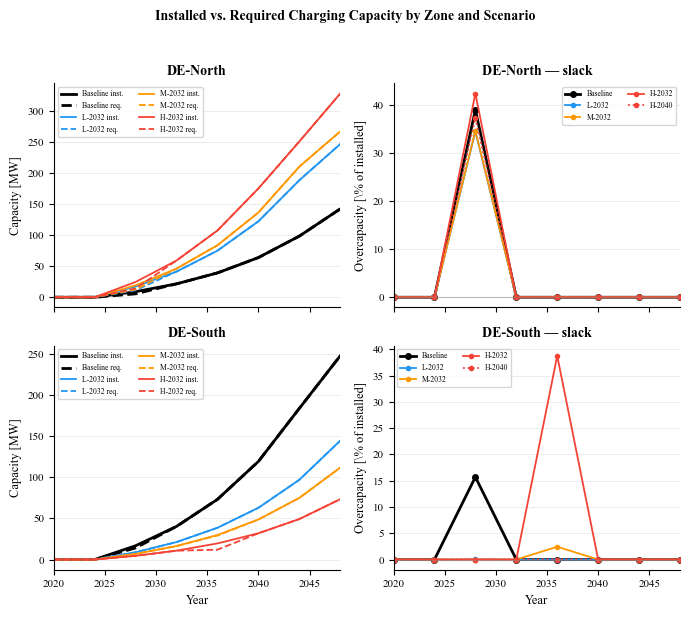


Scenario                  Zone        Installed   Required      Slack   Slack%
                                           [MW]       [MW]       [MW]         
------------------------------------------------------------------------------
Baseline                  DE-North         63.8       63.8        0.0     0.0%
Baseline                  DE-South        119.3      119.3        0.0     0.0%

L-2032                    DE-North        122.1      122.1        0.0     0.0%
L-2032                    DE-South         62.9       62.9        0.0     0.0%

M-2032                    DE-North        136.2      136.2        0.0     0.0%
M-2032                    DE-South         48.7       48.7        0.0     0.0%

H-2032                    DE-North        174.9      174.9        0.0     0.0%
H-2032                    DE-South         32.0       32.0        0.0     0.0%



In [550]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

# ---- Installed vs Required capacity: all scenarios ----
fig, axes = plt.subplots(2, 2, figsize=(7, 6), sharex=True)

for row, zone in enumerate(['DE-North', 'DE-South']):
    # Left: absolute installed vs required
    ax = axes[row, 0]
    for sc_name in ['DE_unified', 'DE_split_low_from2032', 'DE_split_mid_from2032', 'DE_split_high_from2032']:
        info = SCENARIOS[sc_name]
        data = compute_overcapacity(sc_name, zone)
        installed = [d['installed_mw'] for d in data]
        required = [d['required_mw'] for d in data]
        lw = 2.0 if sc_name == 'DE_unified' else 1.3
        ax.plot(YEARS_PLOT, installed, color=info['color'], ls='-', lw=lw,
                label=f"{info['label']} inst.")
        ax.plot(YEARS_PLOT, required, color=info['color'], ls='--', lw=lw,
                label=f"{info['label']} req.")
    
    ax.set_title(f'{zone}', fontweight='bold', fontsize=10)
    if row == 1:
        ax.set_xlabel('Year', fontsize=9)
    ax.set_ylabel('Capacity [MW]', fontsize=9)
    ax.legend(fontsize=5.5, ncol=2, loc='upper left')
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(2020, 2048)

    # Right: overcapacity as % of installed capacity (with dot markers)
    ax = axes[row, 1]
    for sc_name in ['DE_unified', 'DE_split_low_from2032', 'DE_split_mid_from2032', 'DE_split_high_from2032',
                     'DE_split_high_from2040']:
        info = SCENARIOS[sc_name]
        data = compute_overcapacity(sc_name, zone)
        overcap_pct = [d['overcap_mw'] / d['installed_mw'] * 100 if d['installed_mw'] > 0 else 0 for d in data]
        lw = 2.0 if sc_name == 'DE_unified' else 1.3
        ms = 4 if sc_name == 'DE_unified' else 3
        ax.plot(YEARS_PLOT, overcap_pct, color=info['color'], ls=info['ls'], lw=lw,
                marker='o', markersize=ms, label=info['label'])
    
    ax.axhline(0, color='#7F8C8D', lw=0.8, ls='-', alpha=0.5)
    ax.set_title(f'{zone} — slack', fontweight='bold', fontsize=10)
    if row == 1:
        ax.set_xlabel('Year', fontsize=9)
    ax.set_ylabel('Overcapacity [\\% of installed]', fontsize=9)
    ax.legend(fontsize=5.5, ncol=2, loc='best')
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(2020, 2048)

fig.suptitle('Installed vs. Required Charging Capacity by Zone and Scenario',
             fontweight='bold', fontsize=10, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_installed_vs_required.pdf', bbox_inches='tight', dpi=300)
plt.show()

mpl.rcParams['font.family'] = 'sans-serif'

# ---- Print table: installed vs required at 2040 ----
print(f"\n{'Scenario':<25} {'Zone':<10} {'Installed':>10} {'Required':>10} {'Slack':>10} {'Slack%':>8}")
print(f"{'':25} {'':10} {'[MW]':>10} {'[MW]':>10} {'[MW]':>10} {'':>8}")
print("-" * 78)
for sc_name in ['DE_unified', 'DE_split_low_from2032', 'DE_split_mid_from2032', 'DE_split_high_from2032']:
    label = SCENARIOS[sc_name]['label']
    for zone in ['DE-North', 'DE-South']:
        data = compute_overcapacity(sc_name, zone)
        d = next(x for x in data if x['year'] == 2040)
        slack_pct = d['overcap_mw'] / d['installed_mw'] * 100 if d['installed_mw'] > 0 else 0
        print(f"{label:<25} {zone:<10} {d['installed_mw']:>10.1f} {d['required_mw']:>10.1f} "
              f"{d['overcap_mw']:>10.1f} {slack_pct:>7.1f}%")
    print()

  -> also saved to EEM: eem_used_vs_unused_capacity.pdf


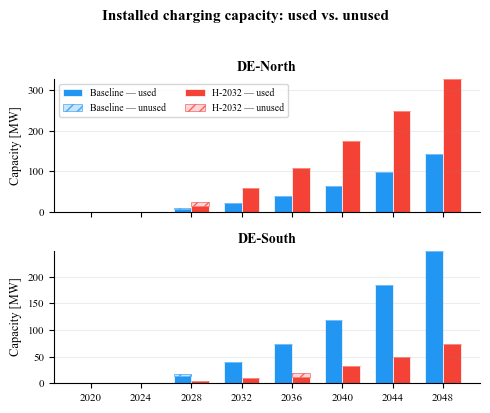

In [551]:
# Stacked bar: used vs unused charging capacity — Baseline and H-2032 side by side
import matplotlib as mpl
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

YEARS_PLOT = [y for y in MODELED_YEARS if y <= 2048]

scenarios_to_plot = [
    ('DE_unified',              'Baseline',    '#2196F3', '#BBDEFB'),
    ('DE_split_high_from2032',  'H-2032',      '#F44336', '#FFCDD2'),
]

fig, axes = plt.subplots(2, 1, figsize=(5, 4), sharex=True)

n_scen = len(scenarios_to_plot)
width = 0.35
offsets = [-width/2, width/2]

for row, zone in enumerate(['DE-North', 'DE-South']):
    ax = axes[row]
    x = np.arange(len(YEARS_PLOT))

    for si, (sc_name, label, color_used, color_unused) in enumerate(scenarios_to_plot):
        data = compute_overcapacity(sc_name, zone)
        required = [d['required_mw'] for d in data]
        unused = [max(d['overcap_mw'], 0) for d in data]

        ax.bar(x + offsets[si], required, width, label=f'{label} — used',
               color=color_used, edgecolor='white', linewidth=0.5)
        ax.bar(x + offsets[si], unused, width, bottom=required, label=f'{label} — unused',
               color=color_unused, edgecolor=color_used, linewidth=0.5,
               hatch='///', alpha=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels([str(y) for y in YEARS_PLOT], fontsize=9)
    ax.set_title(zone, fontweight='bold', fontsize=10)
    ax.set_ylabel('Capacity [MW]', fontsize=9)
    ax.grid(True, alpha=0.15, axis='y', color='#7F8C8D')
    ax.tick_params(labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if row == 0:
        ax.legend(fontsize=7, loc='upper left', ncol=2)

fig.suptitle('Installed charging capacity: used vs. unused',
             fontweight='bold', fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_used_vs_unused_capacity.pdf', bbox_inches='tight', dpi=300)
save_eem(fig, 'eem_used_vs_unused_capacity.pdf')
plt.show()

Saved eem_charging_capacity_by_country_zone.pdf/.png


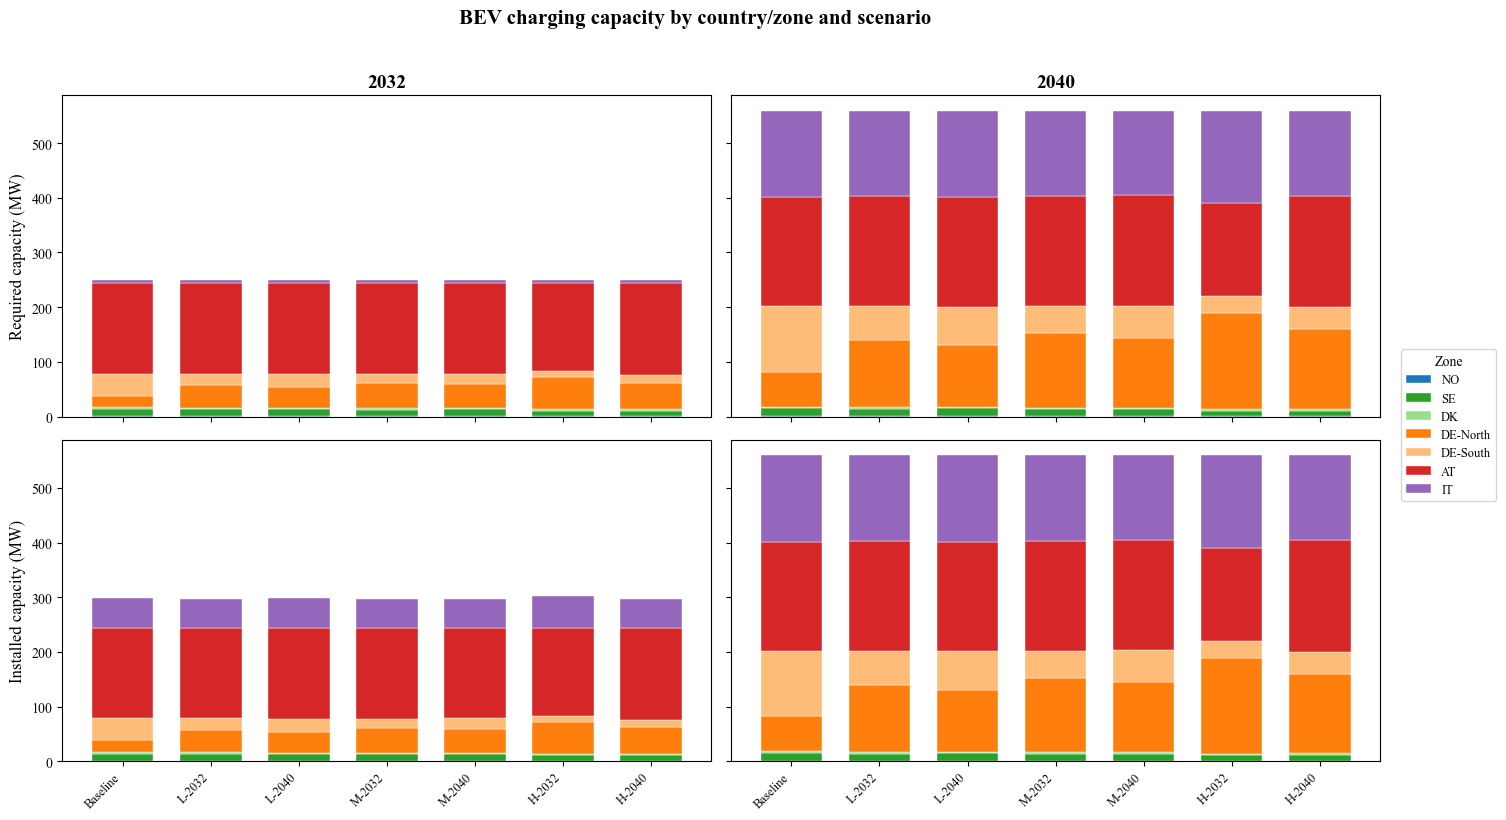

In [552]:
# --- BEV charging: required capacity (from s) and installed capacity (from q) by country/zone ---
# 2x2: top row = required capacity (MW), bottom row = installed capacity (MW)
# Columns: 2032, 2040.  One stacked bar per scenario.

years_to_show = [2032, 2040]
gamma = 0.3

# Collect all zones
all_zones_set = set()
for sc in SCENARIOS:
    for z in all_s[sc]:
        all_zones_set.add(z)
    for z in all_q_elec[sc]:
        all_zones_set.add(z)

zone_order_prio = ['NO', 'FI', 'SE', 'DK', 'DE-North', 'DE-South', 'AT', 'CH', 'IT', 'SI']
zone_order = [z for z in zone_order_prio if z in all_zones_set]
zone_order += sorted(all_zones_set - set(zone_order))

zone_colors = {
    'NO': '#1f77b4', 'FI': '#aec7e8', 'SE': '#2ca02c', 'DK': '#98df8a',
    'DE-North': '#ff7f0e', 'DE-South': '#ffbb78',
    'AT': '#d62728', 'CH': '#ff9896', 'IT': '#9467bd', 'SI': '#c5b0d5',
    'CZ': '#8c564b', 'PL': '#c49c94', 'NL': '#e377c2', 'BE': '#f7b6d2',
    'FR': '#7f7f7f', 'HU': '#c7c7c7', 'HR': '#bcbd22', 'LU': '#dbdb8d',
}
default_colors = plt.cm.tab20.colors
_ci = 0
for z in zone_order:
    if z not in zone_colors:
        zone_colors[z] = default_colors[_ci % len(default_colors)]
        _ci += 1

sc_order = list(SCENARIOS.keys())
sc_labels = [SCENARIOS[sc]['label'] for sc in sc_order]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey='row')

for col, year in enumerate(years_to_show):
    ax_req = axes[0, col]   # required capacity from s
    ax_inst = axes[1, col]  # installed capacity from q

    x = np.arange(len(sc_order))

    # --- Top row: required capacity = s / (gamma * 8760), in MW ---
    bottoms = np.zeros(len(sc_order))
    for zone in zone_order:
        vals = []
        for sc in sc_order:
            s_mwh = all_s[sc].get(zone, {}).get(year, 0)
            vals.append(s_mwh / (gamma * 8760))  # MW
        vals = np.array(vals)
        ax_req.bar(x, vals, bottom=bottoms, width=0.7,
                   label=zone, color=zone_colors.get(zone, '#999'),
                   edgecolor='white', linewidth=0.3)
        bottoms += vals

    ax_req.set_title(f'{year}', fontsize=14, fontweight='bold')
    ax_req.set_xticks(x)
    ax_req.set_xticklabels([] if True else sc_labels)  # labels only on bottom
    if col == 0:
        ax_req.set_ylabel('Required capacity (MW)', fontsize=12)

    # --- Bottom row: installed cumulative q, in MW ---
    bottoms = np.zeros(len(sc_order))
    for zone in zone_order:
        vals = []
        for sc in sc_order:
            cumul_kw = sum(all_q_elec[sc].get(zone, {}).get(y, 0)
                           for y in MODELED_YEARS if y <= year)
            vals.append(cumul_kw / 1e3)  # MW
        vals = np.array(vals)
        ax_inst.bar(x, vals, bottom=bottoms, width=0.7,
                    label=zone, color=zone_colors.get(zone, '#999'),
                    edgecolor='white', linewidth=0.3)
        bottoms += vals

    ax_inst.set_xticks(x)
    ax_inst.set_xticklabels(sc_labels, rotation=45, ha='right', fontsize=9)
    if col == 0:
        ax_inst.set_ylabel('Installed capacity (MW)', fontsize=12)

# Single legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title='Zone', fontsize=9, title_fontsize=10,
           loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=True)

fig.suptitle('BEV charging capacity by country/zone and scenario',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'eem_charging_capacity_by_country_zone.pdf', bbox_inches='tight')
fig.savefig(FIGURES_DIR / 'eem_charging_capacity_by_country_zone.png', dpi=200, bbox_inches='tight')
print("Saved eem_charging_capacity_by_country_zone.pdf/.png")
plt.show()

## Future Work

- **Rolling horizon approach** to approximate stranded (unused) charger capacities: Instead of a single-shot optimization over the full planning horizon, use a rolling-horizon formulation where infrastructure investment decisions are made with limited foresight. This would capture the risk of building charging capacity under one market zone configuration (unified) that becomes underutilized if the zone split occurs later â€” providing a more realistic estimate of stranded infrastructure costs.

In [553]:

# Check country/zone shares for baseline vs high-20% scenarios at 2032 and 2040
import pandas as pd

zones_of_interest = ['NO', 'FI', 'SE', 'DK', 'DE-North', 'DE-South', 'AT', 'CH', 'IT', 'SI', 'CZ', 'PL', 'NL', 'BE', 'FR']

for year in [2032, 2040]:
    rows = []
    for sc in ['DE_unified', 'DE_split_high_from2032', 'DE_split_high_from2032']:
        total = sum(all_s[sc].get(z, {}).get(year, 0) for z in zones_of_interest)
        row = {'scenario': SCENARIOS[sc]['label']}
        for z in zones_of_interest:
            val = all_s[sc].get(z, {}).get(year, 0)
            row[z] = round(val / total * 100, 2) if total > 0 else 0
        rows.append(row)
    df = pd.DataFrame(rows).set_index('scenario')
    print(f"\n=== {year} â€” BEV charging energy share (%) ===")
    print(df.to_string())
    
    # Show absolute change from baseline
    baseline = df.iloc[0]
    print(f"\n  Delta vs baseline (pp):")
    for i in range(1, len(df)):
        delta = df.iloc[i] - baseline
        nonzero = delta[delta.abs() > 0.05]
        print(f"  {df.index[i]}: {nonzero.to_dict()}")



=== 2032 â€” BEV charging energy share (%) ===
            NO   FI    SE    DK  DE-North  DE-South     AT   CH    IT   SI   CZ   PL   NL   BE   FR
scenario                                                                                           
Baseline  0.17  0.0  5.45  1.07      8.61     16.11  66.28  0.0  2.32  0.0  0.0  0.0  0.0  0.0  0.0
H-2032    0.17  0.0  4.16  1.09     23.61      4.31  64.35  0.0  2.30  0.0  0.0  0.0  0.0  0.0  0.0
H-2032    0.17  0.0  4.16  1.09     23.61      4.31  64.35  0.0  2.30  0.0  0.0  0.0  0.0  0.0  0.0

  Delta vs baseline (pp):
  H-2032: {'SE': -1.29, 'DE-North': 15.0, 'DE-South': -11.8, 'AT': -1.9300000000000068}
  H-2032: {'SE': -1.29, 'DE-North': 15.0, 'DE-South': -11.8, 'AT': -1.9300000000000068}

=== 2040 â€” BEV charging energy share (%) ===
            NO   FI    SE    DK  DE-North  DE-South     AT   CH     IT   SI   CZ   PL   NL   BE   FR
scenario                                                                                            

In [554]:

# Required capacity (MW) delta vs baseline for DE-North, DE-South, DK, AT, IT
# This produces the numbers for the manuscript table
gamma = 0.3
zones = ['DE-North', 'DE-South', 'DK', 'AT', 'IT']
sc_split_all = [
    'DE_split_low_from2032', 'DE_split_low_from2040',
    'DE_split_mid_from2032', 'DE_split_mid_from2040',
    'DE_split_high_from2032', 'DE_split_high_from2040',
]
sc_labels = {
    'DE_split_low_from2032': 'L-2032', 'DE_split_low_from2040': 'L-2040',
    'DE_split_mid_from2032': 'M-2032', 'DE_split_mid_from2040': 'M-2040',
    'DE_split_high_from2032': 'H-2032', 'DE_split_high_from2040': 'H-2040',
}

for year in [2032, 2040]:
    print(f"\n{'='*90}")
    print(f"  {year} — Required charging capacity (MW) = s / (gamma * 8760)")
    print(f"{'='*90}")
    
    # Absolute values
    header = f"{'Scenario':<12}"
    for z in zones:
        header += f" | {z:>8}"
    print(header)
    print("-" * len(header))
    
    # Baseline
    row = f"{'Baseline':<12}"
    base = {}
    for z in zones:
        s_mwh = all_s['DE_unified'].get(z, {}).get(year, 0)
        req_mw = s_mwh / (gamma * 8760)
        base[z] = req_mw
        row += f" | {req_mw:>8.1f}"
    print(row)
    
    for sc in sc_split_all:
        row = f"{sc_labels[sc]:<12}"
        for z in zones:
            s_mwh = all_s[sc].get(z, {}).get(year, 0)
            req_mw = s_mwh / (gamma * 8760)
            row += f" | {req_mw:>8.1f}"
        print(row)
    
    # Deltas
    print(f"\n  Delta vs Baseline (MW):")
    header2 = f"  {'Scenario':<10}"
    for z in zones:
        header2 += f" | {z:>8}"
    print(header2)
    print("  " + "-" * (len(header2) - 2))
    
    for sc in sc_split_all:
        row = f"  {sc_labels[sc]:<10}"
        for z in zones:
            s_mwh = all_s[sc].get(z, {}).get(year, 0)
            req_mw = s_mwh / (gamma * 8760)
            delta = req_mw - base[z]
            row += f" | {delta:>+8.1f}"
        print(row)

print("\n\nCopy the 2040 delta table into the manuscript (conference_101719.tex).")


  2032 — Required charging capacity (MW) = s / (gamma * 8760)
Scenario     | DE-North | DE-South |       DK |       AT |       IT
-------------------------------------------------------------------
Baseline     |     21.5 |     40.3 |      2.7 |    165.9 |      5.8
L-2032       |     41.2 |     21.3 |      2.4 |    165.7 |      5.8
L-2040       |     38.0 |     23.9 |      2.2 |    166.4 |      5.8
M-2032       |     46.0 |     16.4 |      2.3 |    166.7 |      5.8
M-2040       |     43.2 |     19.7 |      2.2 |    166.0 |      5.8
H-2032       |     59.1 |     10.8 |      2.7 |    161.1 |      5.8
H-2040       |     49.1 |     13.6 |      2.3 |    168.5 |      5.8

  Delta vs Baseline (MW):
  Scenario   | DE-North | DE-South |       DK |       AT |       IT
  -----------------------------------------------------------------
  L-2032     |    +19.7 |    -19.1 |     -0.3 |     -0.2 |     -0.0
  L-2040     |    +16.5 |    -16.5 |     -0.5 |     +0.5 |     +0.0
  M-2032     |    +24.5 | 

In [555]:

gamma = 0.3
zones = ['DK', 'AT', 'IT']
scs = ['DE_unified', 'DE_split_low_from2032', 'DE_split_mid_from2032', 'DE_split_high_from2032']

for year in [2032, 2040]:
    print(f"\n=== {year} ===")
    print(f"{'Scenario':<22} {'DK req':>7} {'DK inst':>7}  {'AT req':>7} {'AT inst':>7}  {'IT req':>7} {'IT inst':>7}")
    for sc in scs:
        vals = []
        for z in zones:
            req = all_s[sc].get(z, {}).get(year, 0) / (gamma * 8760)
            inst = sum(all_q_elec[sc].get(z, {}).get(y, 0) for y in MODELED_YEARS if y <= year) / 1e3
            vals.extend([req, inst])
        print(f"{SCENARIOS[sc]['label']:<22} {vals[0]:>7.1f} {vals[1]:>7.1f}  {vals[2]:>7.1f} {vals[3]:>7.1f}  {vals[4]:>7.1f} {vals[5]:>7.1f}")
    # delta
    print("  Delta vs Baseline:")
    b = []
    for z in zones:
        b.append(all_s['DE_unified'].get(z, {}).get(year, 0) / (gamma * 8760))
        b.append(sum(all_q_elec['DE_unified'].get(z, {}).get(y, 0) for y in MODELED_YEARS if y <= year) / 1e3)
    for sc in scs[1:]:
        vals = []
        for z in zones:
            req = all_s[sc].get(z, {}).get(year, 0) / (gamma * 8760)
            inst = sum(all_q_elec[sc].get(z, {}).get(y, 0) for y in MODELED_YEARS if y <= year) / 1e3
            vals.extend([req, inst])
        d = [vals[i] - b[i] for i in range(6)]
        print(f"  {SCENARIOS[sc]['label']:<20} {d[0]:>+7.1f} {d[1]:>+7.1f}  {d[2]:>+7.1f} {d[3]:>+7.1f}  {d[4]:>+7.1f} {d[5]:>+7.1f}")



=== 2032 ===
Scenario                DK req DK inst   AT req AT inst   IT req IT inst
Baseline                   2.7     2.7    165.9   165.9      5.8    53.3
L-2032                     2.4     2.4    165.7   165.7      5.8    52.7
M-2032                     2.3     2.3    166.7   166.7      5.8    52.7
H-2032                     2.7     2.7    161.1   161.1      5.8    57.2
  Delta vs Baseline:
  L-2032                  -0.3    -0.3     -0.2    -0.2     -0.0    -0.6
  M-2032                  -0.4    -0.4     +0.8    +0.8     +0.0    -0.6
  H-2032                  +0.1    +0.1     -4.8    -4.8     -0.0    +3.9

=== 2040 ===
Scenario                DK req DK inst   AT req AT inst   IT req IT inst
Baseline                   2.7     2.7    199.8   199.8    157.9   157.9
L-2032                     3.3     3.3    200.7   200.7    156.0   156.0
M-2032                     3.5     3.5    201.7   201.7    156.1   156.1
H-2032                     2.8     2.8    169.1   169.1    169.4   169.4
  

In [556]:

gamma = 0.3
zones = ['DK', 'AT', 'IT']
scs = ['DE_unified', 'DE_split_high_from2032']
for year in [2032, 2040]:
    print(f"\n{year}:")
    for sc in scs:
        r = {}
        for z in zones:
            r[z] = all_s[sc].get(z, {}).get(year, 0) / (gamma*8760)
        print(f"  {SCENARIOS[sc]['label']}: DK={r['DK']:.1f} MW, AT={r['AT']:.1f} MW, IT={r['IT']:.1f} MW")



2032:
  Baseline: DK=2.7 MW, AT=165.9 MW, IT=5.8 MW
  H-2032: DK=2.7 MW, AT=161.1 MW, IT=5.8 MW

2040:
  Baseline: DK=2.7 MW, AT=199.8 MW, IT=157.9 MW
  H-2032: DK=2.8 MW, AT=169.1 MW, IT=169.4 MW


In [557]:
gamma=0.3
for y in [2032,2040]:
 for sc in ['DE_unified','DE_split_high_from2032']:
  dk=all_s[sc].get('DK',{}).get(y,0)/(gamma*8760)
  at=all_s[sc].get('AT',{}).get(y,0)/(gamma*8760)
  it=all_s[sc].get('IT',{}).get(y,0)/(gamma*8760)
  print(f"{y} {SCENARIOS[sc]['label']:>22}: DK={dk:.1f} AT={at:.1f} IT={it:.1f} MW")


2032               Baseline: DK=2.7 AT=165.9 IT=5.8 MW
2032                 H-2032: DK=2.7 AT=161.1 IT=5.8 MW
2040               Baseline: DK=2.7 AT=199.8 IT=157.9 MW
2040                 H-2032: DK=2.8 AT=169.1 IT=169.4 MW


In [558]:
g=0.3;r=lambda s,z,y:s.get(z,{}).get(y,0)/(g*8760)
print("DK",r(all_s['DE_unified'],'DK',2040),r(all_s['DE_split_high_from2032'],'DK',2040))
print("AT",r(all_s['DE_unified'],'AT',2040),r(all_s['DE_split_high_from2032'],'AT',2040))
print("IT",r(all_s['DE_unified'],'IT',2040),r(all_s['DE_split_high_from2032'],'IT',2040))

DK 2.6764194733252906 2.8264208235954955
AT 199.8430262717783 169.1259230916248
IT 157.90431796750158 169.445010857658


In [559]:
print(type(all_s))

<class 'dict'>


In [560]:
g=0.3
a=all_s
print(a['DE_unified'].get('DK',{}).get(2040,0)/(g*8760))

2.6764194733252906


In [561]:
g=0.3
for z in ['DK','AT','IT']:
 b=all_s['DE_unified'].get(z,{}).get(2040,0)/(g*8760)
 h=all_s['DE_split_high_from2032'].get(z,{}).get(2040,0)/(g*8760)
 print(f"{z}: baseline={b:.1f} high20={h:.1f} delta={h-b:+.1f} MW")

DK: baseline=2.7 high20=2.8 delta=+0.2 MW
AT: baseline=199.8 high20=169.1 delta=-30.7 MW
IT: baseline=157.9 high20=169.4 delta=+11.5 MW


In [562]:
g=0.3
for z in ['DK','AT','IT']:
 b=all_s['DE_unified'].get(z,{}).get(2032,0)/(g*8760)
 h=all_s['DE_split_high_from2032'].get(z,{}).get(2032,0)/(g*8760)
 print(f"{z} 2032: baseline={b:.1f} high20={h:.1f} delta={h-b:+.1f} MW")

DK 2032: baseline=2.7 high20=2.7 delta=+0.1 MW
AT 2032: baseline=165.9 high20=161.1 delta=-4.8 MW
IT 2032: baseline=5.8 high20=5.8 delta=-0.0 MW


In [563]:
g=0.3
# Also DE-North and DE-South for context
for z in ['DE-North','DE-South','DK','AT','IT']:
 b40=all_s['DE_unified'].get(z,{}).get(2040,0)/(g*8760)
 h40=all_s['DE_split_high_from2032'].get(z,{}).get(2040,0)/(g*8760)
 print(f"{z:10s} 2040: baseline={b40:>6.1f}  high20={h40:>6.1f}  delta={h40-b40:>+6.1f} MW")

DE-North   2040: baseline=  63.8  high20= 174.9  delta=+111.1 MW
DE-South   2040: baseline= 119.3  high20=  32.0  delta= -87.4 MW
DK         2040: baseline=   2.7  high20=   2.8  delta=  +0.2 MW
AT         2040: baseline= 199.8  high20= 169.1  delta= -30.7 MW
IT         2040: baseline= 157.9  high20= 169.4  delta= +11.5 MW


In [564]:
for sc,v in SCENARIOS.items():
 print(f"{sc:30s} {v['label']}")

DE_unified                     Baseline
DE_split_low_from2032          L-2032
DE_split_low_from2040          L-2040
DE_split_mid_from2032          M-2032
DE_split_mid_from2040          M-2040
DE_split_high_from2032         H-2032
DE_split_high_from2040         H-2040


In [565]:
g=0.3
# Quick overview: all scenarios, 2040, key zones
print(f"{'Scenario':<25} {'DE-N':>6} {'DE-S':>6} {'AT':>6} {'IT':>6} {'Total':>7}")
for sc in SCENARIOS:
 t=0
 vals={}
 for z in ['DE-North','DE-South','AT','IT']:
  v=all_s[sc].get(z,{}).get(2040,0)/(g*8760)
  vals[z]=v; t+=v
 for z in all_s[sc]:
  if z not in vals:
   t+=all_s[sc][z].get(2040,0)/(g*8760)
 print(f"{SCENARIOS[sc]['label']:<25} {vals['DE-North']:>6.1f} {vals['DE-South']:>6.1f} {vals['AT']:>6.1f} {vals['IT']:>6.1f} {t:>7.1f}")

Scenario                    DE-N   DE-S     AT     IT   Total
Baseline                    63.8  119.3  199.8  157.9   559.3
L-2032                     122.1   62.9  200.7  156.0   559.3
L-2040                     112.6   70.6  200.6  157.8   559.3
M-2032                     136.2   48.7  201.7  156.1   559.3
M-2040                     128.0   58.4  201.9  154.6   559.3
H-2032                     174.9   32.0  169.1  169.4   559.3
H-2040                     145.3   40.3  203.6  155.4   559.3


In [566]:
import json
nb = json.load(open(r'D:\AntoniaMariaG\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\eem_results.ipynb'))
for i,c in enumerate(nb['cells']):
    if c.get('id') == 'ka3h5i2xca':
        print(f"Cell index: {i}")
        src = ''.join(c['source'])
        print(src[:500])
        print("---END PREVIEW---")
        break

Cell index: 30
# Route-level BEV share change: Violin plot by corridor type
# Baseline vs H-2032 at 2040

import yaml as _yaml
from collections import defaultdict as _dd
import matplotlib as mpl

# Set Times-like font
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

# Build path -> zone classification
_paths_data2 = _yaml.load(open(INPUT_DIR / 'DE_unified' / 'Path.yaml'), Loader=_yaml.UnsafeLoad
---END PREVIEW---


In [567]:
import json
with open(r'D:\AntoniaMariaG\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\eem_results.ipynb') as f:
    nb=json.load(f)
for i,c in enumerate(nb['cells']):
    if c.get('id')=='ka3h5i2xca':
        print(''.join(c['source']))
        break

# Route-level BEV share change: Violin plot by corridor type
# Baseline vs H-2032 at 2040

import yaml as _yaml
from collections import defaultdict as _dd
import matplotlib as mpl

# Set Times-like font
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif', 'Georgia', 'serif']
mpl.rcParams['mathtext.fontset'] = 'stix'

# Build path -> zone classification
_paths_data2 = _yaml.load(open(INPUT_DIR / 'DE_unified' / 'Path.yaml'), Loader=_yaml.UnsafeLoader)
_path_zones = {}
for p in _paths_data2:
    zones_on_path = [geo_id_to_zone.get(g, '??') for g in p['sequence']]
    has_n = 'DE-North' in zones_on_path
    has_s = 'DE-South' in zones_on_path
    if has_n and has_s:
        _path_zones[p['id']] = 'Cross-zonal'
    elif has_n:
        _path_zones[p['id']] = 'North only'
    elif has_s:
        _path_zones[p['id']] = 'South only'
    else:
        _path_zones[p['id']] = 'Non-DE'

_odpairs2 = _yaml.load(open(INPUT_DIR / 'DE_unified' / 'Odpair.